<a href="https://colab.research.google.com/github/sonalimoorthy/SC4002-NLP-PROJECT-/blob/main/main_stage2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SC4002 NLP Project — Task 1 and Task 2

This notebook trains and compares two RNN models on the MASSIVE English dataset.

- **Task 1 — Intent classification:** predict one of the 60 intent labels for an utterance.
- **Task 2 — Slot filling:** predict a BIO slot label for each token in the utterance.

Both tasks use the same RNN encoder, with a separate output layer for each task.

## Experiments
1. **Unidirectional RNN:** reads the utterance from left to right.
2. **Bidirectional RNN:** reads the utterance from left to right and right to left.

The models use word embeddings, RNNs, softmax outputs and cross-entropy loss, following the SC4002 lecture material.

## 1. Imports and setup

The imports below are used for loading the data, building the neural networks, training them and checking their results.

In [1]:
import json
import random
import re
import tarfile
import time
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cpu


## 2. Load the MASSIVE English dataset

The notebook first checks whether the original JSONL file or a processed train/dev/test split is already available. If neither is found, it downloads the official MASSIVE archive.

In [2]:
DATA_URL = 'https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz'

RAW_JSONL = Path('data/raw/en-US.jsonl')
RAW_ARCHIVE = Path('data/raw/amazon-massive-dataset-1.0.tar.gz')
PROCESSED_DIR = Path('data/processed')

if not RAW_JSONL.is_file() and not RAW_ARCHIVE.is_file():
    for root in [Path('.'), Path('/kaggle/input')]:
        if root.exists():
            files = list(root.rglob('en-US.jsonl'))
            if files:
                RAW_JSONL = files[0]
                print('Found dataset:', RAW_JSONL)
                break

if not RAW_JSONL.is_file() and not RAW_ARCHIVE.is_file():
    for root in [Path('.'), Path('/kaggle/input')]:
        if root.exists():
            files = [p for p in root.rglob('*.tar.gz') if 'massive' in p.name.lower()]
            if files:
                RAW_ARCHIVE = files[0]
                print('Found archive:', RAW_ARCHIVE)
                break

if not RAW_JSONL.is_file() and not RAW_ARCHIVE.is_file():
    RAW_ARCHIVE.parent.mkdir(parents=True, exist_ok=True)
    print('Downloading MASSIVE dataset...')
    urllib.request.urlretrieve(DATA_URL, RAW_ARCHIVE)


## 3. Tokenisation and reading the data

The tokeniser separates words and punctuation and converts tokens to lowercase. The same tokenisation is applied to the utterance and its slot annotations so that each input token has one slot label.

In [3]:
TOKEN_PATTERN = re.compile(r"\w+(?:['’]\w+)*|[^\w\s]", flags=re.UNICODE)
SLOT_PATTERN = re.compile(r'\[([^:\]]+)\s*:\s*(.*?)\]')


def tokenize_utterance(text):
    return [word.lower() for word in TOKEN_PATTERN.findall(str(text))]


def read_jsonl(path):
    rows = []
    with Path(path).open('r', encoding='utf-8-sig') as file:
        for line in file:
            if line.strip():
                rows.append(json.loads(line))
    return rows


def read_archive(path):
    with tarfile.open(path, mode='r:gz') as archive:
        member = next(
            (item for item in archive if item.isfile() and item.name.endswith('/data/en-US.jsonl')),
            None
        )
        if member is None:
            raise FileNotFoundError('Could not find data/en-US.jsonl in the archive')

        stream = archive.extractfile(member)
        if stream is None:
            raise FileNotFoundError('Could not read the MASSIVE JSONL file')

        return [json.loads(line.decode('utf-8')) for line in stream if line.strip()]


def parse_annot_utt(annot_utt):
    words = []
    tags = []
    position = 0

    for match in SLOT_PATTERN.finditer(str(annot_utt)):
        outside = tokenize_utterance(annot_utt[position:match.start()])
        words.extend(outside)
        tags.extend(['O'] * len(outside))

        slot_name = match.group(1).strip()
        slot_words = tokenize_utterance(match.group(2).strip())

        if slot_words:
            words.extend(slot_words)
            tags.append('B-' + slot_name)
            tags.extend(['I-' + slot_name] * (len(slot_words) - 1))

        position = match.end()

    outside = tokenize_utterance(str(annot_utt)[position:])
    words.extend(outside)
    tags.extend(['O'] * len(outside))

    return words, tags


## 4. Prepare train, development and test data

The original MASSIVE partitions are kept. Slot labels are read from the annotated utterance when available. The code also accepts already processed rows that store their slot labels in `slots`, `slot_tags` or `slot_labels`.

In [4]:
def load_processed_splits(folder):
    result = {}
    for split in ['train', 'dev', 'test']:
        file_path = folder / (split + '.jsonl')
        if not file_path.is_file():
            return None
        result[split] = read_jsonl(file_path)
    return result


split_rows = load_processed_splits(PROCESSED_DIR)

if split_rows is not None:
    print('Using processed train/dev/test files.')
else:
    if RAW_JSONL.is_file():
        raw_rows = read_jsonl(RAW_JSONL)
    else:
        raw_rows = read_archive(RAW_ARCHIVE)

    split_rows = {'train': [], 'dev': [], 'test': []}

    for row in raw_rows:
        if row.get('locale') == 'en-US':
            split = row.get('partition')
            if split in split_rows:
                split_rows[split].append(row)

    print('Using original MASSIVE English records.')


data = {}

for split in ['train', 'dev', 'test']:
    cleaned = []

    for row in split_rows[split]:
        utterance = row.get('utt', row.get('utterance'))
        intent = row.get('intent')

        if utterance is None or intent is None:
            raise ValueError(f'{split} row is missing an utterance or intent.')

        if row.get('annot_utt') is not None:
            words, slots = parse_annot_utt(row['annot_utt'])
        else:
            words = row.get('tokens') or tokenize_utterance(utterance)
            slots = row.get('slots')
            if slots is None:
                slots = row.get('slot_tags')
            if slots is None:
                slots = row.get('slot_labels')

            if slots is None:
                raise ValueError(
                    f'{split} row has no slot labels. Check the preprocessing output format.'
                )

            slots = [str(tag) for tag in slots]

        if len(words) != len(slots):
            raise ValueError(
                f'{split} row has {len(words)} tokens but {len(slots)} slot labels. '
                'Check tokenisation and slot alignment.'
            )

        if len(words) == 0:
            words = ['<UNK>']
            slots = ['O']

        cleaned.append({
            'id': row.get('id', ''),
            'utt': str(utterance),
            'tokens': words,
            'intent': str(intent),
            'slots': slots
        })

    data[split] = cleaned

for split in ['train', 'dev', 'test']:
    print(f'{split}: {len(data[split]):,} utterances')

# The brief gives the exact size of each English split, so check that we
# really have all of them (and nothing got dropped while cleaning).
assert len(data['train']) == 11514, f"train has {len(data['train'])} rows, expected 11514"
assert len(data['dev']) == 2033, f"dev has {len(data['dev'])} rows, expected 2033"
assert len(data['test']) == 2974, f"test has {len(data['test'])} rows, expected 2974"
print('OK - split sizes match the brief (11,514 / 2,033 / 2,974)')

print('\nExample:')
print(data['train'][0])

Using original MASSIVE English records.
train: 11,514 utterances
dev: 2,033 utterances
test: 2,974 utterances
OK - split sizes match the brief (11,514 / 2,033 / 2,974)

Example:
{'id': '1', 'utt': 'wake me up at nine am on friday', 'tokens': ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday'], 'intent': 'alarm_set', 'slots': ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']}


## 5. Convert intent and slot labels to IDs

The label mappings are created using the training set. The development and test sets are checked to make sure that they do not contain labels that were not seen during training.

In [5]:
intent_names = sorted({row['intent'] for row in data['train']})
intent2id = {name: index for index, name in enumerate(intent_names)}
id2intent = {index: name for name, index in intent2id.items()}
NUM_INTENTS = len(intent_names)

if NUM_INTENTS != 60:
    raise ValueError(f'Expected 60 intent labels, found {NUM_INTENTS}.')

slot_names = sorted({tag for row in data['train'] for tag in row['slots']})

# Add matching I- labels for slot types that appear with B- in training.
for tag in list(slot_names):
    if tag.startswith('B-'):
        inside_tag = 'I-' + tag[2:]
        if inside_tag not in slot_names:
            slot_names.append(inside_tag)

slot_names = sorted(set(slot_names))
slot2id = {name: index for index, name in enumerate(slot_names)}
id2slot = {index: name for name, index in slot2id.items()}
NUM_SLOTS = len(slot_names)

for split in ['dev', 'test']:
    new_intents = {row['intent'] for row in data[split]} - set(intent2id)
    new_slots = {tag for row in data[split] for tag in row['slots']} - set(slot2id)

    if new_intents:
        raise ValueError(f'Unknown intent labels in {split}: {sorted(new_intents)}')
    if new_slots:
        raise ValueError(f'Unknown slot labels in {split}: {sorted(new_slots)}')

for split in ['train', 'dev', 'test']:
    for row in data[split]:
        row['intent_id'] = intent2id[row['intent']]
        row['slot_ids'] = [slot2id[tag] for tag in row['slots']]

print('Number of intent labels:', NUM_INTENTS)
print('Number of slot labels:', NUM_SLOTS)

intent_table = pd.DataFrame(
    [(i, name) for i, name in enumerate(intent_names[:10])],
    columns=['Intent ID', 'Intent name']
)
display(intent_table)


Number of intent labels: 60
Number of slot labels: 111


,Intent ID,Intent name
0,0,alarm_query
1,1,alarm_remove
2,2,alarm_set
3,3,audio_volume_down
4,4,audio_volume_mute
5,5,audio_volume_other
6,6,audio_volume_up
7,7,calendar_query
8,8,calendar_remove
9,9,calendar_set


## 6. Build the word vocabulary

Each word in the training data is assigned an ID. Words that only appear in development or test data are represented by the unknown token.

In [6]:
PAD_TOKEN = '<PAD>'
UNK_TOKEN = '<UNK>'
PAD_ID = 0
UNK_ID = 1

word_counts = Counter(
    word for row in data['train'] for word in row['tokens']
)

vocab = {PAD_TOKEN: PAD_ID, UNK_TOKEN: UNK_ID}

for word, count in word_counts.most_common():
    if word not in vocab:
        vocab[word] = len(vocab)

VOCAB_SIZE = len(vocab)

for split in ['train', 'dev', 'test']:
    for row in data[split]:
        row['input_ids'] = [vocab.get(word, UNK_ID) for word in row['tokens']]
        row['length'] = len(row['input_ids'])

print('Vocabulary size:', VOCAB_SIZE)
print('Example tokens:', data['train'][0]['tokens'])
print('Example word IDs:', data['train'][0]['input_ids'])
print('Example slot tags:', data['train'][0]['slots'])


Vocabulary size: 5294
Example tokens: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']
Example word IDs: [293, 4, 53, 22, 128, 47, 13, 140]
Example slot tags: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']


## 7. Dataset and batches

Utterances have different lengths, so sequences in a batch are padded to the length of the longest utterance. Padding positions in the slot labels use `-100`, which is ignored by the slot loss.

In [7]:
IGNORE_INDEX = -100
BATCH_SIZE = 64


class MASSIVEDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        return (
            torch.tensor(row['input_ids'], dtype=torch.long),
            torch.tensor(row['intent_id'], dtype=torch.long),
            torch.tensor(row['slot_ids'], dtype=torch.long)
        )


def make_batch(batch):
    words, intents, slots = zip(*batch)

    lengths = torch.tensor([len(x) for x in words], dtype=torch.long)
    words = pad_sequence(words, batch_first=True, padding_value=PAD_ID)
    intents = torch.stack(intents)
    slots = pad_sequence(slots, batch_first=True, padding_value=IGNORE_INDEX)

    return words, lengths, intents, slots


train_loader = DataLoader(
    MASSIVEDataset(data['train']),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=make_batch
)

dev_loader = DataLoader(
    MASSIVEDataset(data['dev']),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=make_batch
)

print('Training batches:', len(train_loader))


Training batches: 180


## 8. Stage-1 model: a joint RNN for intent and slots

This is the Stage-1 model used for both experiments. Only the `bidirectional` flag changes between them.

**Architecture**
1. **Embedding layer.** `nn.Embedding(VOCAB_SIZE, 100)` turns each word ID into a 100-dimensional vector. `<PAD>` (ID 0) is the padding index, so it always stays a zero vector.
2. **RNN encoder.** A single-layer vanilla `nn.RNN` with a `tanh` activation and 96 hidden units, the same Elman RNN as in the lectures: $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$. The padded batch is packed first with `pack_padded_sequence`, so padding never changes the hidden state.
   - Unidirectional: each token output is 96-dimensional.
   - Bidirectional: a forward RNN and a backward RNN are concatenated, so each token output is 192-dimensional.
3. **Two output layers (heads).**
   - **Intent head:** a linear layer applied to the *final* hidden state of the sentence. In the bidirectional model, this is the last forward state concatenated with the last backward state.
   - **Slot head:** a linear layer applied to the hidden state at *every* token position.

**Inputs**
- `words`: a `(batch, max_len)` tensor of word IDs, padded with `PAD_ID`.
- `lengths`: a `(batch,)` tensor holding the real length of each utterance.

**Outputs**
- `intent_scores`: `(batch, 60)` logits, one score per intent.
- `slot_scores`: `(batch, max_len, NUM_SLOTS)` logits, one score vector per token.

The softmax is not a separate layer, because `nn.CrossEntropyLoss` applies log-softmax internally. At prediction time we just take the `argmax`.

**Loss**

$$L = \text{CE}(\text{intent}) + \text{CE}(\text{slots})$$

Both terms are cross-entropy losses. The slot loss uses `ignore_index=-100`, so padded positions add nothing to it. The two terms are simply added with equal weight.

**Optimiser:** plain mini-batch SGD with learning rate 0.05 (no momentum, no weight decay), batch size 64, for 15 epochs.

**Model selection:** after every epoch we evaluate on the dev set and compute a validation score:

$$\text{val score} = \tfrac{1}{2}(\text{intent accuracy} + \text{slot micro F1})$$

We use the average because the model is trained jointly, and selecting on only one of the two metrics would ignore the other task. Whenever the validation score beats the best so far, the checkpoint is saved to disk.

In [8]:
# Hyperparameters for the Stage-1 model
EMBEDDING_DIM = 100
HIDDEN_DIM = 96
EPOCHS = 15
LEARNING_RATE = 0.05


class JointRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim,
                 num_intents, num_slots, bidirectional=False):
        super().__init__()

        self.bidirectional = bidirectional

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID
        )

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=bidirectional,
            nonlinearity='tanh'
        )

        if bidirectional:
            output_size = hidden_dim * 2
        else:
            output_size = hidden_dim

        self.intent_layer = nn.Linear(output_size, num_intents)
        self.slot_layer = nn.Linear(output_size, num_slots)

    def forward(self, words, lengths):
        embedded = self.embedding(words)

        packed_words = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_outputs, last_hidden = self.rnn(packed_words)

        outputs, _ = pad_packed_sequence(
            packed_outputs,
            batch_first=True,
            total_length=words.size(1)
        )

        # Slot filling predicts one label for each token.
        slot_scores = self.slot_layer(outputs)

        # Intent classification uses the final hidden state.
        if self.bidirectional:
            forward_hidden = last_hidden[-2]
            backward_hidden = last_hidden[-1]
            sentence = torch.cat((forward_hidden, backward_hidden), dim=1)
        else:
            sentence = last_hidden[-1]

        intent_scores = self.intent_layer(sentence)

        return intent_scores, slot_scores

## 9. Number of parameters

The brief limits the model to **20M parameters**. We build each model once, just to count its parameters. Every parameter is trainable here, because nothing is frozen and no pretrained embeddings are used, so the total and trainable counts should be equal.

In [9]:
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


MAX_PARAMS = 20_000_000
param_counts = {}

for name, bi in [('Unidirectional RNN', False), ('Bidirectional RNN', True)]:
    temp_model = JointRNN(VOCAB_SIZE, EMBEDDING_DIM, HIDDEN_DIM,
                          NUM_INTENTS, NUM_SLOTS, bidirectional=bi)
    total, trainable = count_parameters(temp_model)
    param_counts[name] = (total, trainable)

    print(f'{name}: total = {total:,} | trainable = {trainable:,}')

    # breakdown per layer, just to see where most of the weights are
    for layer_name, layer in temp_model.named_children():
        n = sum(p.numel() for p in layer.parameters())
        print(f'    {layer_name:<13} {n:>10,}')

    assert total <= MAX_PARAMS, f'{name} has {total:,} parameters, which is over 20M!'

del temp_model
print('\nOK - both models are under the 20M parameter limit')

Unidirectional RNN: total = 564,995 | trainable = 564,995
    embedding        529,400
    rnn               19,008
    intent_layer       5,820
    slot_layer        10,767
Bidirectional RNN: total = 600,419 | trainable = 600,419
    embedding        529,400
    rnn               38,016
    intent_layer      11,580
    slot_layer        21,423

OK - both models are under the 20M parameter limit


## 10. Training and evaluation functions

Both tasks are trained together, and the loss is the sum of the intent and slot cross-entropy losses (see Section 8).

The same `get_scores` function is used for every evaluation in the notebook: during training, after reloading checkpoints, and on the test set. It returns:

- **Intent accuracy:** the percentage of utterances whose intent is predicted correctly.
- **Slot micro F1:** a predicted slot counts as correct only if its slot type *and* its full token span match the gold slot. True positives, false positives and false negatives are pooled over all utterances before F1 is calculated.
- **Loss:** the same joint loss as in training, averaged over the utterances. We use it as the validation loss.

For every epoch we record the training loss, the validation loss, the dev metrics and the time the epoch took. If the validation score (the average of intent accuracy and slot F1) is the best so far, the model is saved straight away. So the checkpoint on disk is always the **best epoch**, not the last one.

In [10]:
OUTPUT_DIR = Path('task1_task2_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)


def get_slot_spans(slot_tags):
    spans = set()
    start = None
    slot_type = None

    for index, tag in enumerate(slot_tags):
        if tag.startswith('B-'):
            if start is not None:
                spans.add((slot_type, start, index))

            start = index
            slot_type = tag[2:]

        elif tag.startswith('I-') and start is not None and tag[2:] == slot_type:
            continue

        else:
            if start is not None:
                spans.add((slot_type, start, index))
                start = None
                slot_type = None

            # Treat an I- tag without a matching open span as a new span.
            if tag.startswith('I-'):
                start = index
                slot_type = tag[2:]

    if start is not None:
        spans.add((slot_type, start, len(slot_tags)))

    return spans


def extract_slot_values(tokens, slot_tags):
    """
    Convert BIO tags into readable [slot_type: slot_span] values.

    Example:
        tokens = ['set', 'alarm', 'for', 'five', 'am']
        tags   = ['O', 'O', 'O', 'B-time', 'I-time']
        output = ['[time: five am]']
    """
    extracted = []
    for slot_type, start, end in sorted(
        get_slot_spans(slot_tags), key=lambda span: (span[1], span[2])
    ):
        span_text = ' '.join(tokens[start:end])
        extracted.append(f'[{slot_type}: {span_text}]')
    return extracted


def format_slot_values(tokens, slot_tags):
    """Format extracted slots as a single readable string."""
    values = extract_slot_values(tokens, slot_tags)
    return '; '.join(values) if values else 'No slots detected'


def get_scores(model, rows):
    loader = DataLoader(
        MASSIVEDataset(rows),
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=make_batch
    )

    model.eval()
    correct_intents = 0
    total_intents = 0
    true_spans = set()
    predicted_spans = set()

    # same loss functions as training, so the validation loss is comparable
    intent_loss_fn = nn.CrossEntropyLoss()
    slot_loss_fn = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
    total_loss = 0.0

    row_number = 0

    with torch.no_grad():
        for words, lengths, intent_labels, slot_labels in loader:
            words = words.to(DEVICE)
            intent_scores, slot_scores = model(words, lengths)

            batch_loss = intent_loss_fn(intent_scores, intent_labels.to(DEVICE)) + slot_loss_fn(
                slot_scores.reshape(-1, NUM_SLOTS),
                slot_labels.to(DEVICE).reshape(-1)
            )
            total_loss += batch_loss.item() * len(intent_labels)

            intent_predictions = intent_scores.argmax(dim=1).cpu().tolist()
            slot_predictions = slot_scores.argmax(dim=2).cpu().tolist()
            slot_labels = slot_labels.tolist()

            for predicted_intent, predicted_slots, actual_intent, actual_slots, length in zip(
                intent_predictions,
                slot_predictions,
                intent_labels.tolist(),
                slot_labels,
                lengths.tolist()
            ):
                if predicted_intent == actual_intent:
                    correct_intents += 1
                total_intents += 1

                predicted_tags = [id2slot[tag] for tag in predicted_slots[:length]]
                actual_tags = [id2slot[tag] for tag in actual_slots[:length]]

                # Include the utterance number so spans from different
                # utterances are counted as separate examples.
                for slot_type, start, end in get_slot_spans(actual_tags):
                    true_spans.add((row_number, slot_type, start, end))

                for slot_type, start, end in get_slot_spans(predicted_tags):
                    predicted_spans.add((row_number, slot_type, start, end))

                row_number += 1

    true_positive = len(true_spans & predicted_spans)
    false_positive = len(predicted_spans - true_spans)
    false_negative = len(true_spans - predicted_spans)

    if (2 * true_positive + false_positive + false_negative) == 0:
        slot_micro_f1 = 0.0
    else:
        slot_micro_f1 = (
            100.0 * (2 * true_positive) /
            (2 * true_positive + false_positive + false_negative)
        )

    intent_accuracy = 100.0 * correct_intents / total_intents

    return {
        'intent_accuracy': intent_accuracy,
        'slot_micro_f1': slot_micro_f1,
        'loss': total_loss / total_intents
    }


def validation_score(scores):
    # we select checkpoints on the average of the two dev metrics
    return (scores['intent_accuracy'] + scores['slot_micro_f1']) / 2


def train_model(model_name, bidirectional, checkpoint_path):
    # re-seed so both experiments start from the same random state
    torch.manual_seed(SEED)

    model = JointRNN(
        vocab_size=VOCAB_SIZE,
        embedding_dim=EMBEDDING_DIM,
        hidden_dim=HIDDEN_DIM,
        num_intents=NUM_INTENTS,
        num_slots=NUM_SLOTS,
        bidirectional=bidirectional
    ).to(DEVICE)

    intent_loss = nn.CrossEntropyLoss()
    slot_loss = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
    optimiser = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)

    history = []
    best_score = -1.0
    best_epoch = 0
    run_start = time.time()

    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.time()

        model.train()
        total_loss = 0.0
        total_rows = 0

        for words, lengths, intent_labels, slot_labels in train_loader:
            words = words.to(DEVICE)
            intent_labels = intent_labels.to(DEVICE)
            slot_labels = slot_labels.to(DEVICE)

            optimiser.zero_grad()

            intent_scores, slot_scores = model(words, lengths)

            loss_intent = intent_loss(intent_scores, intent_labels)
            loss_slots = slot_loss(
                slot_scores.reshape(-1, NUM_SLOTS),
                slot_labels.reshape(-1)
            )

            loss = loss_intent + loss_slots
            loss.backward()
            optimiser.step()

            total_loss += loss.item() * len(intent_labels)
            total_rows += len(intent_labels)

        train_loss = total_loss / total_rows

        # check on the dev set after every epoch
        dev_result = get_scores(model, data['dev'])
        dev_score = validation_score(dev_result)
        epoch_time = time.time() - epoch_start

        history.append({
            'epoch': epoch,
            'training_loss': train_loss,
            'validation_loss': dev_result['loss'],
            'dev_intent_accuracy': dev_result['intent_accuracy'],
            'dev_slot_micro_f1': dev_result['slot_micro_f1'],
            'dev_score': dev_score,
            'epoch_time_s': epoch_time
        })

        # save the model only when the validation score improves
        note = ''
        if dev_score > best_score:
            best_score = dev_score
            best_epoch = epoch
            torch.save({
                'model_state': model.state_dict(),
                'epoch': epoch,
                'val_score': dev_score,
                'vocab_size': VOCAB_SIZE,
                'embedding_dim': EMBEDDING_DIM,
                'hidden_dim': HIDDEN_DIM,
                'num_intents': NUM_INTENTS,
                'num_slots': NUM_SLOTS,
                'bidirectional': bidirectional,
                'vocab': vocab,
                'intent2id': intent2id,
                'slot2id': slot2id
            }, checkpoint_path)
            note = '  <- best so far, saved'

        print(
            f'{model_name} | Epoch {epoch:2d}/{EPOCHS} | '
            f'train loss {train_loss:.4f} | val loss {dev_result["loss"]:.4f} | '
            f'intent acc {dev_result["intent_accuracy"]:.2f}% | '
            f'slot F1 {dev_result["slot_micro_f1"]:.2f}% | '
            f'val score {dev_score:.2f} | {epoch_time:.1f}s{note}'
        )

    total_time = time.time() - run_start

    print(f'\nTotal training time: {total_time:.1f}s ({total_time / EPOCHS:.1f}s per epoch on average)')
    print(f'Best epoch: {best_epoch}')
    print(f'Best validation score (mean of intent acc and slot F1): {best_score:.2f}')
    print(f'Checkpoint file: {checkpoint_path}')

    best_info = {
        'best_epoch': best_epoch,
        'best_score': best_score,
        'checkpoint': checkpoint_path,
        'total_time': total_time
    }

    # note: the model returned here is from the LAST epoch,
    # the best one is on disk and gets reloaded later
    return model, pd.DataFrame(history), best_info


def load_checkpoint(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)

    model = JointRNN(
        vocab_size=checkpoint['vocab_size'],
        embedding_dim=checkpoint['embedding_dim'],
        hidden_dim=checkpoint['hidden_dim'],
        num_intents=checkpoint['num_intents'],
        num_slots=checkpoint['num_slots'],
        bidirectional=checkpoint['bidirectional']
    ).to(DEVICE)

    model.load_state_dict(checkpoint['model_state'])
    model.eval()
    return model, checkpoint

## 11. Experiment 1: Unidirectional RNN

The unidirectional RNN reads the utterance from the first token to the last. Its final hidden state is used for intent classification, and its hidden state at each position is used for slot filling.

In [11]:
rnn_model, rnn_history, rnn_best = train_model(
    model_name='Unidirectional RNN',
    bidirectional=False,
    checkpoint_path=OUTPUT_DIR / 'best_unidirectional_rnn.pt'
)

Unidirectional RNN | Epoch  1/15 | train loss 5.5532 | val loss 4.8303 | intent acc 14.31% | slot F1 0.58% | val score 7.45 | 2.8s  <- best so far, saved
Unidirectional RNN | Epoch  2/15 | train loss 4.6015 | val loss 4.3796 | intent acc 23.32% | slot F1 12.21% | val score 17.76 | 3.1s  <- best so far, saved
Unidirectional RNN | Epoch  3/15 | train loss 4.1287 | val loss 3.9307 | intent acc 32.51% | slot F1 17.28% | val score 24.90 | 3.2s  <- best so far, saved
Unidirectional RNN | Epoch  4/15 | train loss 3.6956 | val loss 3.5463 | intent acc 39.35% | slot F1 19.83% | val score 29.59 | 2.6s  <- best so far, saved
Unidirectional RNN | Epoch  5/15 | train loss 3.3258 | val loss 3.2422 | intent acc 45.40% | slot F1 22.50% | val score 33.95 | 2.6s  <- best so far, saved
Unidirectional RNN | Epoch  6/15 | train loss 3.0406 | val loss 3.0196 | intent acc 49.98% | slot F1 24.01% | val score 36.99 | 2.6s  <- best so far, saved
Unidirectional RNN | Epoch  7/15 | train loss 2.8051 | val loss 2.

## 12. Experiment 2: Bidirectional RNN

The bidirectional RNN reads the utterance in both directions. The final forward and backward states are concatenated for intent classification, and the two directional outputs at each token position are used for slot filling.

In [12]:
birnn_model, birnn_history, birnn_best = train_model(
    model_name='Bidirectional RNN',
    bidirectional=True,
    checkpoint_path=OUTPUT_DIR / 'best_bidirectional_rnn.pt'
)

Bidirectional RNN | Epoch  1/15 | train loss 5.1651 | val loss 4.3506 | intent acc 27.89% | slot F1 7.16% | val score 17.52 | 5.0s  <- best so far, saved
Bidirectional RNN | Epoch  2/15 | train loss 4.0499 | val loss 3.7440 | intent acc 38.86% | slot F1 15.11% | val score 26.98 | 3.9s  <- best so far, saved
Bidirectional RNN | Epoch  3/15 | train loss 3.4899 | val loss 3.3138 | intent acc 45.55% | slot F1 21.58% | val score 33.56 | 4.0s  <- best so far, saved
Bidirectional RNN | Epoch  4/15 | train loss 3.0896 | val loss 2.9938 | intent acc 52.24% | slot F1 25.48% | val score 38.86 | 5.0s  <- best so far, saved
Bidirectional RNN | Epoch  5/15 | train loss 2.7805 | val loss 2.7513 | intent acc 57.21% | slot F1 28.60% | val score 42.91 | 4.0s  <- best so far, saved
Bidirectional RNN | Epoch  6/15 | train loss 2.5372 | val loss 2.5661 | intent acc 60.90% | slot F1 30.78% | val score 45.84 | 4.0s  <- best so far, saved
Bidirectional RNN | Epoch  7/15 | train loss 2.3368 | val loss 2.4270 |

## 13. Reload the best checkpoints and evaluate them

The models still in memory come from the *last* epoch, so we don't use them for evaluation. Instead we load each saved checkpoint from disk into a fresh `JointRNN`, then evaluate it on dev and test. There is no further training at this point.

As a sanity check, the dev validation score of the reloaded model should be the same as the best score printed during training. If it isn't, the wrong checkpoint was saved or loaded.

In [13]:
reloaded = {}

for name, best_info in [('Unidirectional RNN', rnn_best), ('Bidirectional RNN', birnn_best)]:
    model, checkpoint = load_checkpoint(best_info['checkpoint'])

    dev_result = get_scores(model, data['dev'])
    test_result = get_scores(model, data['test'])
    reloaded_score = validation_score(dev_result)

    print(f'{name}  (loaded {best_info["checkpoint"]}, saved at epoch {checkpoint["epoch"]})')
    print(f'  dev  -> intent acc {dev_result["intent_accuracy"]:.2f}% | slot F1 {dev_result["slot_micro_f1"]:.2f}% | val score {reloaded_score:.2f}')
    print(f'  test -> intent acc {test_result["intent_accuracy"]:.2f}% | slot F1 {test_result["slot_micro_f1"]:.2f}%')
    print(f'  best val score during training: {best_info["best_score"]:.4f} | after reload: {reloaded_score:.4f}')

    # the reloaded model has to give the same dev score as when it was saved
    assert abs(reloaded_score - best_info['best_score']) < 1e-4, \
        f'{name}: reloaded score {reloaded_score:.4f} does not match {best_info["best_score"]:.4f}'
    print('  OK - reloaded checkpoint matches the best epoch\n')

    reloaded[name] = {'model': model, 'dev': dev_result, 'test': test_result}

Unidirectional RNN  (loaded task1_task2_outputs/best_unidirectional_rnn.pt, saved at epoch 15)
  dev  -> intent acc 65.52% | slot F1 35.33% | val score 50.43
  test -> intent acc 64.06% | slot F1 34.46%
  best val score during training: 50.4262 | after reload: 50.4262
  OK - reloaded checkpoint matches the best epoch

Bidirectional RNN  (loaded task1_task2_outputs/best_bidirectional_rnn.pt, saved at epoch 15)
  dev  -> intent acc 70.98% | slot F1 43.31% | val score 57.15
  test -> intent acc 69.20% | slot F1 41.92%
  best val score during training: 57.1457 | after reload: 57.1457
  OK - reloaded checkpoint matches the best epoch



## 14. Compare the two experiments (report table)

The table below collects everything the report needs for each model: parameter counts, the number of epochs, the best epoch, training time, and the dev and test scores of the **reloaded** checkpoints.

The final model is chosen by **dev validation score only**, using the same criterion as checkpoint selection (the average of intent accuracy and slot F1). The test numbers are reported but never used to make a choice.

In [14]:
report_rows = []

for name, history, best_info in [
    ('Unidirectional RNN', rnn_history, rnn_best),
    ('Bidirectional RNN', birnn_history, birnn_best)
]:
    total, trainable = param_counts[name]
    dev_result = reloaded[name]['dev']
    test_result = reloaded[name]['test']

    report_rows.append({
        'Model': name,
        'Total params': total,
        'Trainable params': trainable,
        'Epochs trained': len(history),
        'Best epoch': best_info['best_epoch'],
        'Train time (s)': best_info['total_time'],
        'Avg time / epoch (s)': history['epoch_time_s'].mean(),
        'Dev intent acc (%)': dev_result['intent_accuracy'],
        'Dev slot F1 (%)': dev_result['slot_micro_f1'],
        'Dev val score': validation_score(dev_result),
        'Test intent acc (%)': test_result['intent_accuracy'],
        'Test slot F1 (%)': test_result['slot_micro_f1'],
        'Checkpoint': best_info['checkpoint'].name
    })

results = pd.DataFrame(report_rows)
display(results.round(2))

best_name = results.sort_values('Dev val score', ascending=False).iloc[0]['Model']

best_model = reloaded[best_name]['model']
if best_name == 'Unidirectional RNN':
    best_history = rnn_history
    best_info = rnn_best
else:
    best_history = birnn_history
    best_info = birnn_best

print('Selected model (highest dev validation score):', best_name)
print('Using checkpoint:', best_info['checkpoint'])

,Model,Total params,Trainable params,Epochs trained,Best epoch,Train time (s),Avg time / epoch (s),Dev intent acc (%),Dev slot F1 (%),Dev val score,Test intent acc (%),Test slot F1 (%),Checkpoint
0,Unidirectional RNN,564995,564995,15,15,43.47,2.89,65.52,35.33,50.43,64.06,34.46,best_unidirectional_rnn.pt
1,Bidirectional RNN,600419,600419,15,15,64.84,4.31,70.98,43.31,57.15,69.20,41.92,best_bidirectional_rnn.pt


Selected model (highest dev validation score): Bidirectional RNN
Using checkpoint: task1_task2_outputs/best_bidirectional_rnn.pt


## 15. Learning curves

The first row shows the training and validation loss of each model, with a dashed line at the epoch whose checkpoint was kept. The other plots show how dev intent accuracy and slot micro F1 changed from epoch to epoch.

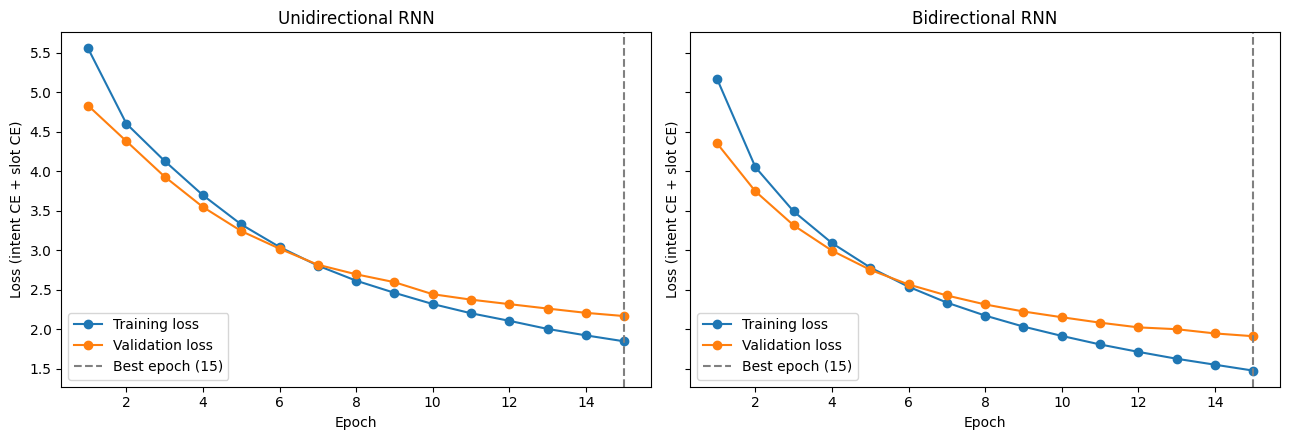

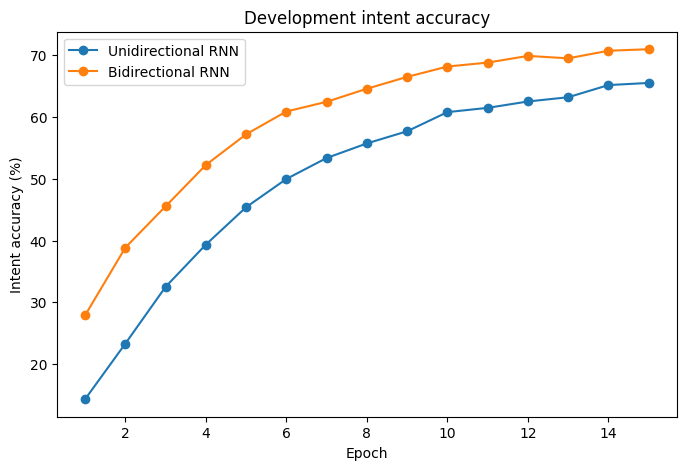

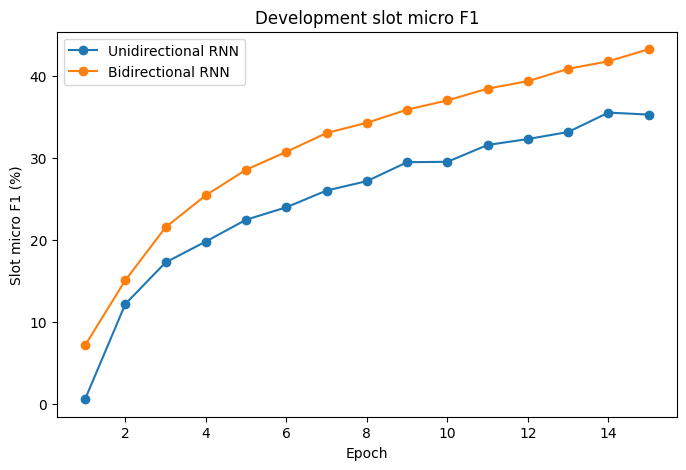

In [15]:
# training vs validation loss for each model
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, (name, history, info) in zip(axes, [
    ('Unidirectional RNN', rnn_history, rnn_best),
    ('Bidirectional RNN', birnn_history, birnn_best)
]):
    ax.plot(history['epoch'], history['training_loss'], marker='o', label='Training loss')
    ax.plot(history['epoch'], history['validation_loss'], marker='o', label='Validation loss')
    ax.axvline(info['best_epoch'], color='grey', linestyle='--',
               label=f"Best epoch ({info['best_epoch']})")
    ax.set_title(name)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss (intent CE + slot CE)')
    ax.legend()

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(rnn_history['epoch'], rnn_history['dev_intent_accuracy'], marker='o', label='Unidirectional RNN')
plt.plot(birnn_history['epoch'], birnn_history['dev_intent_accuracy'], marker='o', label='Bidirectional RNN')
plt.xlabel('Epoch')
plt.ylabel('Intent accuracy (%)')
plt.title('Development intent accuracy')
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(rnn_history['epoch'], rnn_history['dev_slot_micro_f1'], marker='o', label='Unidirectional RNN')
plt.plot(birnn_history['epoch'], birnn_history['dev_slot_micro_f1'], marker='o', label='Bidirectional RNN')
plt.xlabel('Epoch')
plt.ylabel('Slot micro F1 (%)')
plt.title('Development slot micro F1')
plt.legend()
plt.show()

## 16. Final test evaluation

This uses the selected model as it was **reloaded from its checkpoint** (Section 13), not the last-epoch model left in memory. Both metrics are percentages with two decimal places.

- Intent accuracy: the number of correct intent predictions divided by the number of utterances.
- Slot micro F1: exact matches of slot type and token span, pooled over all test utterances.

In [16]:
test_scores = get_scores(best_model, data['test'])

print('Selected model:', best_name)
print('Checkpoint:', best_info['checkpoint'], f"(epoch {best_info['best_epoch']})")
print(f'Test intent accuracy: {test_scores["intent_accuracy"]:.2f}%')
print(f'Test slot micro F1: {test_scores["slot_micro_f1"]:.2f}%')

Selected model: Bidirectional RNN
Checkpoint: task1_task2_outputs/best_bidirectional_rnn.pt (epoch 15)
Test intent accuracy: 69.20%
Test slot micro F1: 41.92%


## Readable slot extraction output

The model continues to train and predict using BIO tags (`B-time`, `I-time`, `O`, etc.), since these labels identify token boundaries. For the final output, consecutive BIO tags are decoded into readable slot-value pairs such as `[time: five am]`.

The test prediction CSV stores the readable values in `true_slots` and `predicted_slots`. The original token-level BIO sequences are also retained in `true_bio_tags` and `predicted_bio_tags` for debugging and evaluation.

## 17. Test predictions and output files

The output folder contains the test predictions of the selected model, the report table, the per-epoch history of both runs, the final test metrics, and the two best checkpoints (which were saved during training).

In [17]:
test_loader = DataLoader(
    MASSIVEDataset(data['test']),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=make_batch
)

prediction_rows = []
best_model.eval()

with torch.no_grad():
    for words, lengths, intent_labels, slot_labels in test_loader:
        words = words.to(DEVICE)
        intent_scores, slot_scores = best_model(words, lengths)

        intent_predictions = intent_scores.argmax(dim=1).cpu().tolist()
        slot_predictions = slot_scores.argmax(dim=2).cpu().tolist()

        for i, predicted_intent in enumerate(intent_predictions):
            length = lengths[i].item()
            predicted_slots = slot_predictions[i][:length]
            row_index = len(prediction_rows)
            original = data['test'][row_index]

            prediction_rows.append({
                'id': original['id'],
                'utterance': original['utt'],
                'true_intent': original['intent'],
                'predicted_intent': id2intent[predicted_intent],
                # Human-readable slot extraction: [slot_type: slot span]
                'true_slots': format_slot_values(
                    original['tokens'], original['slots']
                ),
                'predicted_slots': format_slot_values(
                    original['tokens'],
                    [id2slot[tag] for tag in predicted_slots]
                ),
                # Keep token-level BIO tags as optional diagnostic columns.
                'true_bio_tags': ' '.join(original['slots']),
                'predicted_bio_tags': ' '.join(
                    id2slot[tag] for tag in predicted_slots
                )
            })

pd.DataFrame(prediction_rows).to_csv(
    OUTPUT_DIR / 'test_predictions.csv',
    index=False
)

results.to_csv(OUTPUT_DIR / 'report_table.csv', index=False, float_format='%.2f')
rnn_history.to_csv(OUTPUT_DIR / 'history_unidirectional_rnn.csv', index=False)
birnn_history.to_csv(OUTPUT_DIR / 'history_bidirectional_rnn.csv', index=False)

pd.DataFrame([{
    'selected_model': best_name,
    'checkpoint': best_info['checkpoint'].name,
    'best_epoch': best_info['best_epoch'],
    'test_intent_accuracy': test_scores['intent_accuracy'],
    'test_slot_micro_f1': test_scores['slot_micro_f1']
}]).to_csv(OUTPUT_DIR / 'test_metrics.csv', index=False, float_format='%.2f')

# no need to torch.save again here - the best checkpoints were already
# written during training (best_unidirectional_rnn.pt / best_bidirectional_rnn.pt)

print('Files saved in:', OUTPUT_DIR.resolve())

Files saved in: /content/task1_task2_outputs


## 18. Predict an intent and slots for a new utterance

This uses the same tokenisation and vocabulary as the training data, together with the selected model reloaded from its checkpoint. The model returns one intent, plus one slot label for each token.

Note that the official **slot micro F1** is the one pooled over the full dev or test set in Section 10. Nothing here changes it.

In [18]:
def predict_utterance(utterance):
    words = tokenize_utterance(utterance)

    if not words:
        words = [UNK_TOKEN]

    word_ids = [vocab.get(word, UNK_ID) for word in words]
    input_words = torch.tensor(
        [word_ids],
        dtype=torch.long,
        device=DEVICE
    )
    lengths = torch.tensor([len(word_ids)], dtype=torch.long)

    best_model.eval()

    with torch.no_grad():
        intent_scores, slot_scores = best_model(input_words, lengths)

        intent_id = int(intent_scores.argmax(dim=1).item())
        slot_ids = slot_scores.argmax(dim=2)[0].cpu().tolist()

    predicted_intent = id2intent[intent_id]
    predicted_slots = [
        id2slot[index] for index in slot_ids[:len(words)]
    ]

    extracted_slots = extract_slot_values(words, predicted_slots)

    result = {
        'utterance': utterance,
        'predicted_intent': predicted_intent,
        'tokens': words,
        # Readable output requested: [slot_type: slot span]
        'predicted_slots': extracted_slots,
        # BIO tags are retained for debugging/evaluation if needed.
        'predicted_bio_tags': predicted_slots
    }

    return result


# Predict intent and slots for a new utterance.
result = predict_utterance('Set an alarm for 7 am tomorrow')

print('Utterance:', result['utterance'])
print('Predicted intent:', result['predicted_intent'])
print('Tokens:', result['tokens'])
print('Extracted slots:', '; '.join(result['predicted_slots']) if result['predicted_slots'] else 'No slots detected')
print('BIO tags:', result['predicted_bio_tags'])



Utterance: Set an alarm for 7 am tomorrow
Predicted intent: alarm_set
Tokens: ['set', 'an', 'alarm', 'for', '7', 'am', 'tomorrow']
Extracted slots: [time: 7 am]; [date: tomorrow]
BIO tags: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'B-date']


---

# Stage 2: AI-Assisted Improvement

Everything above this point is the **Stage 1 baseline**, built without generative AI. Everything from here on is **Stage 2**, in which the team worked with an AI tool to find the baseline's weaknesses and improve the joint system.

**AI tool used:** Claude Opus 5.5 (Anthropic), through claude.ai, on 10 November 2026. The full conversation is saved in `ai_collaboration.md`.

**How Stage 2 works**
1. **Error analysis (Section 19).** The selected Stage 1 model (bidirectional RNN) is analysed on the **dev set only**, to see where and why it fails.
2. **AI suggestions and team decisions (Section 20).** Each suggestion is accepted, modified or rejected, with the reason.
3. **Improved model (Sections 21–24).** The accepted changes are built step by step, so each group of changes can be measured separately.
4. **Model selection on dev, then one test evaluation (Sections 25–26).** The Stage 2 system is compared with the Stage 1 baseline.
5. **Error analysis of the improved system (Sections 27–28),** including error cases for the report.

**Rules followed (same as Stage 1)**
- Same MASSIVE en-US splits, same tokenisation, same `data`, `vocab`, `intent2id` and `slot2id` built in Stage 1. Nothing is added to or removed from the training set.
- Training uses the **train split only**. The dev split is used for early stopping and model selection. The test split is used **once**, after the final model has been chosen.
- Slot micro F1 uses the same `get_slot_spans` function and the same formula as Stage 1 (checked with an assert in Section 19).
- No pretrained models. The only pretrained component is **GloVe word vectors**, which the brief allows. The whole system stays far below 20M parameters (checked in Section 23).

## 19. Baseline error analysis (dev set)

First we collect the selected baseline's predictions on the dev set. `score_predictions` computes intent accuracy and slot micro F1 from a list of predictions, using the same `get_slot_spans` function and formula as `get_scores` in Section 10. Stage 2 needs this because a CRF model does not produce its slot tags with a simple `argmax`. The assert below checks that `score_predictions` gives **exactly** the same numbers as `get_scores` on the baseline, so the Stage 1 and Stage 2 results are comparable.

The diagnosis looks at:
- **Training progress:** whether the baseline had finished learning after 15 epochs.
- **Unknown words:** how often dev utterances contain words that never appeared in training, and how much worse the model does on them.
- **Invalid BIO sequences:** `I-X` tags that do not follow `B-X` or `I-X`. A per-token `argmax` cannot prevent these.
- **Utterance length:** whether longer utterances are harder for the vanilla RNN.
- **Intent errors:** the worst intents and the most frequent confusions.
- **Slot errors:** the worst slot types, and whether slot errors are wrong types, wrong boundaries, missed slots or spurious slots.

In [19]:
from collections import defaultdict


def baseline_predict(model, rows):
    """Intent IDs and BIO tag lists predicted by a Stage 1 JointRNN."""
    loader = DataLoader(MASSIVEDataset(rows), batch_size=BATCH_SIZE,
                        shuffle=False, collate_fn=make_batch)
    pred_intents, pred_tags = [], []
    model.eval()
    with torch.no_grad():
        for words, lengths, _, _ in loader:
            intent_scores, slot_scores = model(words.to(DEVICE), lengths)
            pred_intents += intent_scores.argmax(dim=1).cpu().tolist()
            for seq, length in zip(slot_scores.argmax(dim=2).cpu().tolist(), lengths.tolist()):
                pred_tags.append([id2slot[t] for t in seq[:length]])
    return pred_intents, pred_tags


def score_predictions(rows, pred_intents, pred_tags):
    """Same metrics and formula as get_scores (Section 10), computed from predictions."""
    correct = sum(int(p == row['intent_id']) for p, row in zip(pred_intents, rows))
    true_spans, predicted_spans = set(), set()
    for n, (row, tags) in enumerate(zip(rows, pred_tags)):
        true_spans |= {(n,) + span for span in get_slot_spans(row['slots'])}
        predicted_spans |= {(n,) + span for span in get_slot_spans(tags)}

    tp = len(true_spans & predicted_spans)
    fp = len(predicted_spans - true_spans)
    fn = len(true_spans - predicted_spans)
    f1 = 0.0 if (2 * tp + fp + fn) == 0 else 100.0 * 2 * tp / (2 * tp + fp + fn)
    return {'intent_accuracy': 100.0 * correct / len(rows), 'slot_micro_f1': f1}


def count_invalid_bio(tag_seqs):
    """Number of I-X tags that do not follow B-X or I-X."""
    invalid = 0
    for tags in tag_seqs:
        previous = 'O'
        for tag in tags:
            if tag.startswith('I-') and (previous == 'O' or previous[2:] != tag[2:]):
                invalid += 1
            previous = tag
    return invalid


def slot_error_breakdown(rows, pred_tags):
    """Sort every gold slot into one outcome, and count spurious predicted slots."""
    counts = Counter()

    def overlaps(a, b):
        return a[1] < b[2] and b[1] < a[2]

    for row, tags in zip(rows, pred_tags):
        gold = get_slot_spans(row['slots'])
        pred = get_slot_spans(tags)
        for g in gold:
            if g in pred:
                counts['correct'] += 1
            elif any(q[1:] == g[1:] for q in pred):
                counts['right span, wrong type'] += 1
            elif any(q[0] == g[0] and overlaps(q, g) for q in pred):
                counts['right type, wrong boundary'] += 1
            elif any(overlaps(q, g) for q in pred):
                counts['wrong type and boundary'] += 1
            else:
                counts['missed (nothing predicted there)'] += 1
        counts['spurious (no gold slot there)'] += sum(
            1 for q in pred if not any(overlaps(q, g) for g in gold)
        )
    return counts


def per_slot_type_scores(rows, pred_tags):
    tp, fp, fn = Counter(), Counter(), Counter()
    for row, tags in zip(rows, pred_tags):
        gold = get_slot_spans(row['slots'])
        pred = get_slot_spans(tags)
        for s in gold & pred:
            tp[s[0]] += 1
        for s in pred - gold:
            fp[s[0]] += 1
        for s in gold - pred:
            fn[s[0]] += 1
    table = []
    for slot_type in sorted(set(tp) | set(fp) | set(fn)):
        p = tp[slot_type] / (tp[slot_type] + fp[slot_type]) if tp[slot_type] + fp[slot_type] else 0.0
        r = tp[slot_type] / (tp[slot_type] + fn[slot_type]) if tp[slot_type] + fn[slot_type] else 0.0
        f = 2 * p * r / (p + r) if p + r else 0.0
        table.append({'Slot type': slot_type, 'Support': tp[slot_type] + fn[slot_type],
                      'Precision (%)': 100 * p, 'Recall (%)': 100 * r, 'F1 (%)': 100 * f})
    return pd.DataFrame(table)


def diagnose(rows, pred_intents, pred_tags, title, show=True):
    """Error analysis used for both the baseline and the Stage 2 model."""
    summary = {}
    overall = score_predictions(rows, pred_intents, pred_tags)
    summary['Intent accuracy (%)'] = overall['intent_accuracy']
    summary['Slot micro F1 (%)'] = overall['slot_micro_f1']

    # unknown words (not in the Stage 1 training vocabulary)
    has_oov = [any(w not in vocab for w in row['tokens']) for row in rows]
    oov_tokens = sum(w not in vocab for row in rows for w in row['tokens'])
    all_tokens = sum(len(row['tokens']) for row in rows)
    summary['Tokens not in training vocab (%)'] = 100 * oov_tokens / all_tokens
    summary['Utterances with >=1 unknown word (%)'] = 100 * sum(has_oov) / len(rows)
    for label, keep in [('with unknown words', True), ('without unknown words', False)]:
        idx = [i for i, flag in enumerate(has_oov) if flag == keep]
        if idx:
            s = score_predictions([rows[i] for i in idx], [pred_intents[i] for i in idx],
                                  [pred_tags[i] for i in idx])
            summary[f'Intent acc, utterances {label} (%)'] = s['intent_accuracy']
            summary[f'Slot F1, utterances {label} (%)'] = s['slot_micro_f1']

    # invalid BIO
    summary['Invalid I- tags predicted'] = count_invalid_bio(pred_tags)

    # length buckets
    length_rows = []
    for low, high in [(1, 4), (5, 8), (9, 12), (13, 999)]:
        idx = [i for i, row in enumerate(rows) if low <= len(row['tokens']) <= high]
        if idx:
            s = score_predictions([rows[i] for i in idx], [pred_intents[i] for i in idx],
                                  [pred_tags[i] for i in idx])
            length_rows.append({'Length (tokens)': f'{low}-{high}' if high < 999 else f'{low}+',
                                'Utterances': len(idx),
                                'Intent acc (%)': s['intent_accuracy'],
                                'Slot F1 (%)': s['slot_micro_f1']})
    by_length = pd.DataFrame(length_rows)

    # intents
    per_intent = defaultdict(lambda: [0, 0])
    confusions = Counter()
    for p, row in zip(pred_intents, rows):
        per_intent[row['intent']][1] += 1
        if p == row['intent_id']:
            per_intent[row['intent']][0] += 1
        else:
            confusions[(row['intent'], id2intent[p])] += 1
    intent_table = pd.DataFrame(
        [{'Intent': k, 'Support': v[1], 'Accuracy (%)': 100 * v[0] / v[1]} for k, v in per_intent.items()]
    ).sort_values(['Accuracy (%)', 'Support'], ascending=[True, False])
    confusion_table = pd.DataFrame(
        [{'True intent': t, 'Predicted intent': p, 'Count': c} for (t, p), c in confusions.most_common(10)]
    )

    # slots
    slot_table = per_slot_type_scores(rows, pred_tags).sort_values('F1 (%)')
    breakdown = slot_error_breakdown(rows, pred_tags)
    gold_total = sum(v for k, v in breakdown.items() if not k.startswith('spurious'))
    breakdown_table = pd.DataFrame(
        [{'Outcome': k, 'Count': v,
          '% of gold slots': (100 * v / gold_total) if not k.startswith('spurious') else float('nan')}
         for k, v in breakdown.items()]
    )

    if show:
        print(f'===== {title} =====')
        for k, v in summary.items():
            print(f'  {k:<48} {v:.2f}' if isinstance(v, float) else f'  {k:<48} {v}')
        print('\nPerformance by utterance length:')
        display(by_length.round(2))
        print('10 worst intents:')
        display(intent_table.head(10).round(2))
        print('10 most frequent intent confusions:')
        display(confusion_table)
        print('10 worst slot types (support >= 10):')
        display(slot_table[slot_table['Support'] >= 10].head(10).round(2))
        print('What happened to each gold slot:')
        display(breakdown_table.round(2))

    return {'summary': summary, 'by_length': by_length, 'intents': intent_table,
            'confusions': confusion_table, 'slots': slot_table, 'slot_errors': breakdown_table}


# 1) Predictions of the selected Stage 1 model on dev
baseline_dev_intents, baseline_dev_tags = baseline_predict(best_model, data['dev'])

# 2) Check that score_predictions matches get_scores exactly
check_new = score_predictions(data['dev'], baseline_dev_intents, baseline_dev_tags)
check_old = get_scores(best_model, data['dev'])
assert abs(check_new['intent_accuracy'] - check_old['intent_accuracy']) < 1e-9
assert abs(check_new['slot_micro_f1'] - check_old['slot_micro_f1']) < 1e-9
print(f"OK - score_predictions matches get_scores on dev: "
      f"intent acc {check_new['intent_accuracy']:.2f}%, slot F1 {check_new['slot_micro_f1']:.2f}%\n")

# 3) Was the baseline still improving when training stopped?
print('Last 4 epochs of the selected baseline:')
display(best_history[['epoch', 'training_loss', 'validation_loss',
                      'dev_intent_accuracy', 'dev_slot_micro_f1']].tail(4).round(4))
print(f"Best epoch = {best_info['best_epoch']} of {EPOCHS}"
      + ('  -> the best epoch is the LAST epoch, so the model was still improving.'
         if best_info['best_epoch'] == EPOCHS else ''))

# 4) The <UNK> embedding is never trained in Stage 1
unk_in_train = sum(row['input_ids'].count(UNK_ID) for row in data['train'])
print(f'\n<UNK> tokens seen during Stage 1 training: {unk_in_train}'
      + ('  -> the <UNK> vector stays at its random initial value.' if unk_in_train == 0 else ''))
print()

# 5) Full diagnosis
baseline_diag = diagnose(data['dev'], baseline_dev_intents, baseline_dev_tags,
                         f'Stage 1 baseline ({best_name}), dev set')

OK - score_predictions matches get_scores on dev: intent acc 70.98%, slot F1 43.31%

Last 4 epochs of the selected baseline:


,epoch,training_loss,validation_loss,dev_intent_accuracy,dev_slot_micro_f1
11,12,1.7136,2.0235,69.8967,39.4112
12,13,1.6265,2.0004,69.5032,40.9209
13,14,1.5511,1.9469,70.7329,41.8380
14,15,1.4763,1.9116,70.9788,43.3125


Best epoch = 15 of 15  -> the best epoch is the LAST epoch, so the model was still improving.

<UNK> tokens seen during Stage 1 training: 0  -> the <UNK> vector stays at its random initial value.

===== Stage 1 baseline (Bidirectional RNN), dev set =====
  Intent accuracy (%)                              70.98
  Slot micro F1 (%)                                43.31
  Tokens not in training vocab (%)                 3.27
  Utterances with >=1 unknown word (%)             17.90
  Intent acc, utterances with unknown words (%)    57.14
  Slot F1, utterances with unknown words (%)       22.76
  Intent acc, utterances without unknown words (%) 74.00
  Slot F1, utterances without unknown words (%)    47.45
  Invalid I- tags predicted                        172

Performance by utterance length:


,Length (tokens),Utterances,Intent acc (%),Slot F1 (%)
0,1-4,448,64.73,33.70
1,5-8,1057,75.69,46.27
2,9-12,401,70.57,42.29
3,13+,127,55.12,41.38


10 worst intents:


,Intent,Support,Accuracy (%)
11,general_greet,2,0.00
27,music_dislikeness,2,0.00
36,cooking_query,2,0.00
16,iot_hue_lighton,5,20.00
45,email_addcontact,5,20.00
47,recommendation_movies,12,25.00
3,general_quirky,105,33.33
35,recommendation_events,26,38.46
30,music_likeness,16,43.75
58,email_querycontact,16,43.75


... (2 outputs left out)

10 worst slot types (support >= 10):


,Slot type,Support,Precision (%),Recall (%),F1 (%)
2,artist_name,45,0.0,0.0,0.0
4,audiobook_name,16,0.0,0.0,0.0
5,business_name,58,0.0,0.0,0.0
9,color_type,16,0.0,0.0,0.0
22,general_frequency,15,0.0,0.0,0.0
20,game_name,18,0.0,0.0,0.0
27,meal_type,12,0.0,0.0,0.0
42,radio_name,21,0.0,0.0,0.0
44,song_name,23,0.0,0.0,0.0
33,news_topic,40,0.0,0.0,0.0


What happened to each gold slot:


,Outcome,Count,% of gold slots
0,spurious (no gold slot there),89,NaN
1,missed (nothing predicted there),1016,50.50
2,correct,693,34.44
3,"right span, wrong type",38,1.89
4,"right type, wrong boundary",191,9.49
5,wrong type and boundary,74,3.68


### Main weaknesses of the baseline

The output above gives the exact numbers. These are the weaknesses we took to the AI tool:

- **W1. Undertrained.** The best epoch is the last of the 15 epochs, and the validation loss is still falling. Plain SGD with a fixed learning rate of 0.05 learns slowly, so the baseline stopped before it converged.
- **W2. Vanilla RNN encoder.** A `tanh` Elman RNN suffers from vanishing gradients. The intent head only sees the **final** hidden state, so information from early words in the utterance fades. Compare the length table above: longer utterances do worse.
- **W3. Unknown words.** Every training word is in the vocabulary, so `<UNK>` never appears during training and its embedding stays random. Any dev or test word not seen in training (names, places, rare words, numbers) therefore becomes a meaningless vector. See the gap between utterances with and without unknown words above.
- **W4. Invalid and badly bounded slot spans.** Each token's tag is chosen independently with `argmax`, so the model can output `I-X` without a `B-X` before it. The slot error breakdown shows how many gold slots are lost to boundary errors and to missed slots.
- **W5. The two tasks do not share decisions.** The slot layer never sees what the intent head thinks, although the intent strongly constrains which slots can appear (for example `alarm_set` → `time`).

## 20. AI suggestions and team decisions

We gave the AI tool the Stage 1 code, the training logs, the error analysis above and the assignment rules, and asked how to improve the joint system. The table lists its suggestions and our decisions.

| # | AI suggestion | Weakness | Decision | Reason |
|---|---|---|---|---|
| 1 | Replace the vanilla RNN with a 2-layer bidirectional **LSTM** | W2 | **Accept** | LSTM gates reduce vanishing gradients. It is still an RNN from the lectures, and the parameter cost is small. |
| 2 | Train with **Adam** (lr 0.001), **gradient clipping**, up to 30 epochs with **early stopping** on the dev validation score | W1 | **Accept** | The baseline had not converged. Early stopping on dev keeps the test set untouched. |
| 3 | **Dropout** on the embeddings and the LSTM outputs | W1 | **Accept** | Needed once the model trains longer, to stop it overfitting the 11,514 training utterances. |
| 4 | Initialise word embeddings with **GloVe** (100-d, Wikipedia + Gigaword) and fine-tune them | W3 | **Accept** | Word vectors are the one pretrained component the brief allows. We load vectors only for words in our training vocabulary, so the embedding table stays the same size as in Stage 1. |
| 5 | **Word dropout:** during training, replace words that occur only once with `<UNK>` (probability 0.5) | W3 | **Accept** | This lets the `<UNK>` vector actually be learned, so unseen words at test time are no longer random noise. It does not add or change any training example. |
| 6 | Add a **character-level CNN** word representation | W3 | **Accept** | Unseen words (names, numbers like `7am`, typos) still have informative spelling. |
| 7 | Add a **CRF** output layer for slots, decoded with Viterbi | W4 | **Modify** | Accepted, and we also forbid invalid BIO transitions (`O → I-X`, `B-X → I-Y`) inside the CRF. This guarantees that every predicted slot is a well-formed span. |
| 8 | Use **self-attention** to build the sentence vector for intent classification | W2 | **Modify** | We use a simpler **attention pooling** over all LSTM states instead of a multi-head self-attention layer. It is easier to explain and fixes the "only the final state" problem. |
| 9 | Slot-gated model: feed the **intent representation into the slot classifier** | W5 | **Modify** | Instead of a learned gate, we simply concatenate the sentence vector to every token's LSTM output before the slot layer. Same idea, fewer moving parts. |
| 10 | Train a **Transformer encoder** from scratch | – | **Reject** | 11.5k short utterances is little data for a Transformer trained from scratch, and it would be much harder to tune within the deadline. |
| 11 | Fine-tune a **pretrained language model** (e.g. BERT) | – | **Reject** | Not allowed: only word vectors may be pretrained. |
| 12 | **Data augmentation** (back-translation, synonym swaps, LLM-generated utterances) | – | **Reject** | Not allowed: the training set must not be augmented with external or AI-generated examples. |
| 13 | Retrain the final model on **train + dev** | – | **Reject** | Not allowed: train on the training split only, and dev is needed for model selection. |
| 14 | **Ensemble** several models | – | **Reject** | Several times the training cost for a small gain, and harder to analyse. |

To show which changes actually help, the accepted changes are added in **three steps** (Section 24). Each step is trained on train and selected on dev:

| Step | Model | Changes |
|---|---|---|
| S2-A | BiLSTM + better training | 1, 2, 3 |
| S2-B | + better word representations | S2-A + 4, 5, 6 |
| S2-C | + structured outputs (full model) | S2-B + 7, 8, 9 |

The Stage 2 system is whichever of the three has the best **dev** validation score, using the same criterion as Stage 1 (the mean of intent accuracy and slot micro F1).

## 21. GloVe word vectors and character inputs

**GloVe.** We download the 100-dimensional GloVe vectors (`glove-wiki-gigaword-100`, 400k words, about 130 MB) once and keep only the rows for words in the Stage 1 training vocabulary. Training words not in GloVe get small random vectors with the same scale as GloVe. If the download fails, the code falls back to random initialisation and says so; in that case S2-B and S2-C run without GloVe and the report must say so too.

**Characters.** Each token is also stored as a list of character IDs (at most 20 characters). The character vocabulary is built from the training split only.

**Word dropout.** We mark the training words that occur exactly once. During training, each of these is replaced by `<UNK>` with probability 0.5, so the model learns a useful `<UNK>` vector. The input is only masked this way in the training loop; the data itself is not changed.

In [20]:
import gzip
import torch.nn.functional as F

GLOVE_URL = ('https://github.com/RaRe-Technologies/gensim-data/releases/download/'
             'glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz')
GLOVE_PATH = Path('data/glove/glove-wiki-gigaword-100.gz')
GLOVE_DIM = 100


def load_glove_matrix(vocab, path, dim):
    rng = np.random.default_rng(SEED)
    found = {}
    with gzip.open(path, 'rt', encoding='utf-8') as file:
        for line_number, line in enumerate(file):
            parts = line.rstrip().split(' ')
            if line_number == 0 and len(parts) == 2:
                continue  # header line: "<number of words> <dimension>"
            if len(parts) != dim + 1:
                continue
            if parts[0] in vocab:
                found[parts[0]] = np.asarray(parts[1:], dtype=np.float32)

    scale = float(np.std(np.stack(list(found.values())))) if found else 0.1
    matrix = rng.normal(0.0, scale, size=(len(vocab), dim)).astype(np.float32)
    for word, index in vocab.items():
        if word in found:
            matrix[index] = found[word]
    matrix[PAD_ID] = 0.0
    return torch.tensor(matrix), len(found)


GLOVE_MATRIX = None
try:
    if not GLOVE_PATH.is_file():
        GLOVE_PATH.parent.mkdir(parents=True, exist_ok=True)
        print('Downloading GloVe vectors (about 130 MB)...')
        urllib.request.urlretrieve(GLOVE_URL, GLOVE_PATH)
    GLOVE_MATRIX, glove_hits = load_glove_matrix(vocab, GLOVE_PATH, GLOVE_DIM)
    real_words = VOCAB_SIZE - 2  # without <PAD> and <UNK>
    print(f'GloVe vectors found for {glove_hits:,} of {real_words:,} training-vocabulary words '
          f'({100 * glove_hits / real_words:.2f}%)')
except Exception as error:
    print('WARNING: could not load GloVe, using random embeddings instead.')
    print('Reason:', repr(error))

USE_GLOVE = GLOVE_MATRIX is not None
print('Using GloVe:', USE_GLOVE)

# ----- character vocabulary (training split only) -----
MAX_WORD_LEN = 20
CHAR_PAD_ID, CHAR_UNK_ID = 0, 1
char_vocab = {'<PAD>': CHAR_PAD_ID, '<UNK>': CHAR_UNK_ID}
for row in data['train']:
    for word in row['tokens']:
        for ch in word:
            if ch not in char_vocab:
                char_vocab[ch] = len(char_vocab)
CHAR_VOCAB_SIZE = len(char_vocab)

for split in ['train', 'dev', 'test']:
    for row in data[split]:
        row['char_ids'] = [[char_vocab.get(ch, CHAR_UNK_ID) for ch in word[:MAX_WORD_LEN]] or [CHAR_UNK_ID]
                           for word in row['tokens']]

# ----- singleton words for word dropout -----
singleton_ids = torch.zeros(VOCAB_SIZE, dtype=torch.bool)
for word, count in word_counts.items():
    if count == 1:
        singleton_ids[vocab[word]] = True
singleton_ids = singleton_ids.to(DEVICE)

print('Character vocabulary size:', CHAR_VOCAB_SIZE)
print(f'Training words that occur once: {int(singleton_ids.sum()):,} of {VOCAB_SIZE - 2:,}')

GloVe vectors found for 4,914 of 5,292 training-vocabulary words (92.86%)
Using GloVe: True
Character vocabulary size: 34
Training words that occur once: 2,531 of 5,292


## 22. Stage 2 model: BiLSTM encoder with optional char-CNN, attention and CRF

One class covers all three Stage 2 steps; the config switches each component on or off.

**Architecture (full model, S2-C)**
1. **Word embedding** (100-d, GloVe-initialised, fine-tuned) concatenated with a **character CNN** vector (30-d character embeddings → 50 filters of width 3 → max-pool over the characters of each word).
2. **Embedding dropout**, then a **2-layer bidirectional LSTM** with 128 hidden units per direction (so 256-d token outputs), with dropout between layers and on the outputs. Padding is packed exactly as in Stage 1.
3. **Intent head:** attention pooling. Each token gets a score $e_t = v^\top \tanh(W h_t)$, the scores are softmaxed over the real tokens, and the sentence vector is $s = \sum_t \alpha_t h_t$. A linear layer maps $s$ to the 60 intents.
4. **Slot head:** for every token, $[h_t ; s]$ (token output plus the sentence vector) goes through a linear layer, giving one emission score per BIO tag.
5. **CRF:** learns a score for each tag-to-tag transition. Transitions that would create an invalid BIO sequence (`O → I-X`, `B-X → I-Y`, `I-X → I-Y` for X ≠ Y, and starting with `I-X`) are fixed at −10,000, so Viterbi decoding never outputs them.

**Loss:** $L = \text{CE}(\text{intent}) + L_{\text{slot}}$. Without the CRF, $L_{\text{slot}}$ is the token cross-entropy as in Stage 1. With the CRF, it is the CRF negative log-likelihood **divided by the number of tokens in the batch**, so it stays on the same per-token scale and the two tasks keep roughly equal weight, as in Stage 1. Because the slot loss is defined differently, Stage 1 and S2-C loss values are not directly comparable. The comparison uses intent accuracy and slot F1.

In [21]:
class CRF(nn.Module):
    """Linear-chain CRF with hard BIO constraints."""

    def __init__(self, tag_names):
        super().__init__()
        k = len(tag_names)
        self.transitions = nn.Parameter(torch.zeros(k, k))   # [from, to]
        self.start = nn.Parameter(torch.zeros(k))
        self.end = nn.Parameter(torch.zeros(k))

        allowed = torch.ones(k, k, dtype=torch.bool)
        start_allowed = torch.ones(k, dtype=torch.bool)
        for j, to_tag in enumerate(tag_names):
            if to_tag.startswith('I-'):
                start_allowed[j] = False
                for i, from_tag in enumerate(tag_names):
                    if from_tag[2:] != to_tag[2:] or from_tag == 'O':
                        allowed[i, j] = False
        self.register_buffer('allowed', allowed)
        self.register_buffer('start_allowed', start_allowed)

    def _scores(self):
        trans = self.transitions.masked_fill(~self.allowed, -1e4)
        start = self.start.masked_fill(~self.start_allowed, -1e4)
        return trans, start

    def neg_log_likelihood(self, emissions, tags, mask):
        """Per-sentence negative log-likelihood. emissions (B,T,K), tags (B,T), mask (B,T)."""
        trans, start = self._scores()
        batch, length, _ = emissions.shape
        maskf = mask.float()

        # score of the gold path
        gold = start[tags[:, 0]] + emissions[:, 0].gather(1, tags[:, :1]).squeeze(1)
        for t in range(1, length):
            step = trans[tags[:, t - 1], tags[:, t]] + emissions[:, t].gather(1, tags[:, t:t + 1]).squeeze(1)
            gold = gold + step * maskf[:, t]
        last_tags = tags.gather(1, (mask.sum(1) - 1).unsqueeze(1)).squeeze(1)
        gold = gold + self.end[last_tags]

        # log partition function (forward algorithm)
        alpha = start.unsqueeze(0) + emissions[:, 0]
        for t in range(1, length):
            nxt = torch.logsumexp(alpha.unsqueeze(2) + trans.unsqueeze(0), dim=1) + emissions[:, t]
            alpha = torch.where(mask[:, t].unsqueeze(1), nxt, alpha)
        log_z = torch.logsumexp(alpha + self.end.unsqueeze(0), dim=1)
        return log_z - gold

    def decode(self, emissions, mask):
        """Viterbi decoding. Returns one list of tag IDs per sentence."""
        trans, start = self._scores()
        batch, length, _ = emissions.shape
        score = start.unsqueeze(0) + emissions[:, 0]
        backpointers = []
        for t in range(1, length):
            best, index = (score.unsqueeze(2) + trans.unsqueeze(0)).max(dim=1)
            backpointers.append(index)
            score = torch.where(mask[:, t].unsqueeze(1), best + emissions[:, t], score)
        score = score + self.end.unsqueeze(0)

        lengths = mask.sum(1).tolist()
        last = score.argmax(1).tolist()
        backpointers = [bp.cpu() for bp in backpointers]
        paths = []
        for b in range(batch):
            path = [last[b]]
            for t in range(lengths[b] - 1, 0, -1):
                path.append(int(backpointers[t - 1][b, path[-1]]))
            paths.append(path[::-1])
        return paths


class JointBiLSTM(nn.Module):
    def __init__(self, cfg, embedding_matrix=None):
        super().__init__()
        self.cfg = cfg
        self.word_embedding = nn.Embedding(VOCAB_SIZE, cfg['embedding_dim'], padding_idx=PAD_ID)
        if embedding_matrix is not None:
            self.word_embedding.weight.data.copy_(embedding_matrix)

        input_dim = cfg['embedding_dim']
        if cfg['use_char']:
            self.char_embedding = nn.Embedding(CHAR_VOCAB_SIZE, cfg['char_dim'], padding_idx=CHAR_PAD_ID)
            self.char_cnn = nn.Conv1d(cfg['char_dim'], cfg['char_filters'], kernel_size=3, padding=1)
            input_dim += cfg['char_filters']

        self.embedding_dropout = nn.Dropout(cfg['dropout'])
        self.lstm = nn.LSTM(input_dim, cfg['hidden_dim'], num_layers=cfg['num_layers'],
                            batch_first=True, bidirectional=True,
                            dropout=cfg['dropout'] if cfg['num_layers'] > 1 else 0.0)
        self.output_dropout = nn.Dropout(cfg['dropout'])
        hidden = 2 * cfg['hidden_dim']

        if cfg['use_attention']:
            self.attention = nn.Sequential(nn.Linear(hidden, hidden), nn.Tanh(),
                                           nn.Linear(hidden, 1, bias=False))
        self.intent_layer = nn.Linear(hidden, NUM_INTENTS)
        self.slot_layer = nn.Linear(2 * hidden if cfg['intent_to_slot'] else hidden, NUM_SLOTS)
        self.crf = CRF(slot_names) if cfg['use_crf'] else None

    def encode(self, words, chars, lengths):
        batch, length = words.shape
        x = self.word_embedding(words)
        if self.cfg['use_char']:
            c = self.char_embedding(chars)                       # B, T, W, C
            c = c.view(batch * length, chars.size(2), -1).transpose(1, 2)
            c = torch.relu(self.char_cnn(c)).max(dim=2).values   # B*T, F
            x = torch.cat([x, c.view(batch, length, -1)], dim=2)
        x = self.embedding_dropout(x)

        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, (h_n, _) = self.lstm(packed)
        outputs, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=length)
        outputs = self.output_dropout(outputs)

        mask = torch.arange(length, device=words.device).unsqueeze(0) < lengths.to(words.device).unsqueeze(1)

        if self.cfg['use_attention']:
            weights = self.attention(outputs).squeeze(2).masked_fill(~mask, -1e9)
            weights = torch.softmax(weights, dim=1)
            sentence = (weights.unsqueeze(2) * outputs).sum(dim=1)
        else:
            sentence = self.output_dropout(torch.cat([h_n[-2], h_n[-1]], dim=1))

        intent_scores = self.intent_layer(sentence)
        slot_input = outputs
        if self.cfg['intent_to_slot']:
            slot_input = torch.cat([outputs, sentence.unsqueeze(1).expand(-1, length, -1)], dim=2)
        slot_scores = self.slot_layer(slot_input)
        return intent_scores, slot_scores, mask

    def forward(self, words, chars, lengths):
        intent_scores, slot_scores, _ = self.encode(words, chars, lengths)
        return intent_scores, slot_scores

    def loss(self, words, chars, lengths, intent_labels, slot_labels):
        intent_scores, slot_scores, mask = self.encode(words, chars, lengths)
        intent_loss = F.cross_entropy(intent_scores, intent_labels)
        if self.crf is None:
            slot_loss = F.cross_entropy(slot_scores.reshape(-1, NUM_SLOTS), slot_labels.reshape(-1),
                                        ignore_index=IGNORE_INDEX)
        else:
            tags = slot_labels.clamp(min=0)
            slot_loss = self.crf.neg_log_likelihood(slot_scores, tags, mask).sum() / mask.sum()
        return intent_loss + slot_loss

    def predict(self, words, chars, lengths):
        intent_scores, slot_scores, mask = self.encode(words, chars, lengths)
        intents = intent_scores.argmax(dim=1).cpu().tolist()
        if self.crf is None:
            ids = slot_scores.argmax(dim=2).cpu().tolist()
            tags = [seq[:n] for seq, n in zip(ids, lengths.tolist())]
        else:
            tags = self.crf.decode(slot_scores, mask)
        return intents, tags


# ----- quick checks before training -----
def check_gold_bio():
    """Every gold sequence must be allowed by the CRF constraints, otherwise its loss would explode."""
    crf = CRF(slot_names)
    bad = 0
    for row in data['train']:
        ids = row['slot_ids']
        if not crf.start_allowed[ids[0]]:
            bad += 1
            continue
        bad += any(not crf.allowed[a, b] for a, b in zip(ids, ids[1:]))
    return bad


invalid_gold = check_gold_bio()
print('Training utterances whose gold tags break the BIO constraints:', invalid_gold)
assert invalid_gold == 0

Training utterances whose gold tags break the BIO constraints: 0


## 23. Stage 2 configurations and parameter counts

All three steps share the same hyperparameters. Only the switches change. The hyperparameters were chosen as common defaults for BiLSTM taggers before training. Only early stopping and the S2-A/B/C choice are decided with the dev set.

In [22]:
STAGE2_COMMON = {
    'embedding_dim': GLOVE_DIM,
    'hidden_dim': 128,
    'num_layers': 2,
    'dropout': 0.33,
    'char_dim': 30,
    'char_filters': 50,
    'learning_rate': 1e-3,
    'batch_size': 32,
    'max_epochs': 30,
    'patience': 5,          # stop after 5 epochs without a better dev validation score
    'grad_clip': 5.0,
    'word_dropout': 0.5,    # probability of replacing a singleton word with <UNK>
}

STAGE2_CONFIGS = {
    'S2-A BiLSTM': dict(STAGE2_COMMON, use_glove=False, use_char=False, use_word_dropout=False,
                        use_attention=False, intent_to_slot=False, use_crf=False),
    'S2-B + GloVe/char/word-dropout': dict(STAGE2_COMMON, use_glove=USE_GLOVE, use_char=True,
                                           use_word_dropout=True, use_attention=False,
                                           intent_to_slot=False, use_crf=False),
    'S2-C + attention/intent-to-slot/CRF': dict(STAGE2_COMMON, use_glove=USE_GLOVE, use_char=True,
                                                use_word_dropout=True, use_attention=True,
                                                intent_to_slot=True, use_crf=True),
}

stage2_param_counts = {}
for name, cfg in STAGE2_CONFIGS.items():
    temp_model = JointBiLSTM(cfg)
    total, trainable = count_parameters(temp_model)
    stage2_param_counts[name] = (total, trainable)
    print(f'{name}: total = {total:,} | trainable = {trainable:,}')
    for layer_name, layer in temp_model.named_children():
        n = sum(p.numel() for p in layer.parameters())
        if n:
            print(f'    {layer_name:<18} {n:>10,}')
    assert total <= MAX_PARAMS, f'{name} has {total:,} parameters, which is over 20M!'
del temp_model
print('\nOK - every Stage 2 model is under the 20M parameter limit '
      '(the GloVe vectors used are counted inside word_embedding)')

S2-A BiLSTM: total = 1,204,131 | trainable = 1,204,131
    word_embedding        529,400
    lstm                  630,784
    intent_layer           15,420
    slot_layer             28,527
S2-B + GloVe/char/word-dropout: total = 1,260,901 | trainable = 1,260,901
    word_embedding        529,400
    char_embedding          1,020
    char_cnn                4,550
    lstm                  681,984
    intent_layer           15,420
    slot_layer             28,527
S2-C + attention/intent-to-slot/CRF: total = 1,367,908 | trainable = 1,367,908
    word_embedding        529,400
    char_embedding          1,020
    char_cnn                4,550
    lstm                  681,984
    attention              66,048
    intent_layer           15,420
    slot_layer             56,943
    crf                    12,543

OK - every Stage 2 model is under the 20M parameter limit (the GloVe vectors used are counted inside word_embedding)


## 24. Train the three Stage 2 steps

The training loop has the same structure as Stage 1. After every epoch we record the training loss, validation loss, dev metrics and epoch time, and the checkpoint is saved whenever the dev validation score (the mean of intent accuracy and slot F1) improves. The differences are Adam, gradient clipping, word dropout, and **early stopping**: training ends after 5 epochs without improvement, or after 30 epochs.

`evaluate_stage2` gets the predictions and scores them with `score_predictions`, which was checked against `get_scores` in Section 19.

Training all three models takes a few minutes on a GPU and longer on a CPU. The CRF model is the slowest.

In [23]:
STAGE2_DIR = Path('stage2_outputs')
STAGE2_DIR.mkdir(exist_ok=True)


class Stage2Dataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        return row['input_ids'], row['char_ids'], row['intent_id'], row['slot_ids']


def make_batch_s2(batch):
    words, chars, intents, slots = zip(*batch)
    lengths = torch.tensor([len(w) for w in words], dtype=torch.long)
    max_len = int(lengths.max())
    max_word = max(len(c) for sent in chars for c in sent)

    word_tensor = torch.full((len(batch), max_len), PAD_ID, dtype=torch.long)
    slot_tensor = torch.full((len(batch), max_len), IGNORE_INDEX, dtype=torch.long)
    char_tensor = torch.full((len(batch), max_len, max_word), CHAR_PAD_ID, dtype=torch.long)
    for i, (w, c, s) in enumerate(zip(words, chars, slots)):
        word_tensor[i, :len(w)] = torch.tensor(w)
        slot_tensor[i, :len(s)] = torch.tensor(s)
        for j, word_chars in enumerate(c):
            char_tensor[i, j, :len(word_chars)] = torch.tensor(word_chars)
    return word_tensor, char_tensor, lengths, torch.tensor(intents, dtype=torch.long), slot_tensor


def evaluate_stage2(model, rows):
    loader = DataLoader(Stage2Dataset(rows), batch_size=64, shuffle=False, collate_fn=make_batch_s2)
    model.eval()
    pred_intents, pred_tags = [], []
    total_loss = 0.0
    with torch.no_grad():
        for words, chars, lengths, intent_labels, slot_labels in loader:
            words, chars = words.to(DEVICE), chars.to(DEVICE)
            intent_labels, slot_labels = intent_labels.to(DEVICE), slot_labels.to(DEVICE)
            total_loss += model.loss(words, chars, lengths, intent_labels, slot_labels).item() * len(intent_labels)
            intents, tag_ids = model.predict(words, chars, lengths)
            pred_intents += intents
            pred_tags += [[id2slot[t] for t in seq] for seq in tag_ids]
    scores = score_predictions(rows, pred_intents, pred_tags)
    scores['loss'] = total_loss / len(rows)
    return scores, pred_intents, pred_tags


def train_stage2(model_name, cfg, checkpoint_path):
    torch.manual_seed(SEED)
    random.seed(SEED)
    np.random.seed(SEED)

    model = JointBiLSTM(cfg, GLOVE_MATRIX if cfg['use_glove'] else None).to(DEVICE)
    optimiser = torch.optim.Adam(model.parameters(), lr=cfg['learning_rate'])
    loader = DataLoader(Stage2Dataset(data['train']), batch_size=cfg['batch_size'],
                        shuffle=True, collate_fn=make_batch_s2)

    history = []
    best_score, best_epoch, epochs_without_gain = -1.0, 0, 0
    run_start = time.time()

    for epoch in range(1, cfg['max_epochs'] + 1):
        epoch_start = time.time()
        model.train()
        total_loss, total_rows = 0.0, 0

        for words, chars, lengths, intent_labels, slot_labels in loader:
            words, chars = words.to(DEVICE), chars.to(DEVICE)
            intent_labels, slot_labels = intent_labels.to(DEVICE), slot_labels.to(DEVICE)

            if cfg['use_word_dropout']:
                drop = singleton_ids[words] & (torch.rand(words.shape, device=DEVICE) < cfg['word_dropout'])
                words = words.masked_fill(drop, UNK_ID)

            optimiser.zero_grad()
            loss = model.loss(words, chars, lengths, intent_labels, slot_labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            optimiser.step()

            total_loss += loss.item() * len(intent_labels)
            total_rows += len(intent_labels)

        train_loss = total_loss / total_rows
        dev_result, _, _ = evaluate_stage2(model, data['dev'])
        dev_score = validation_score(dev_result)
        epoch_time = time.time() - epoch_start

        history.append({
            'epoch': epoch,
            'training_loss': train_loss,
            'validation_loss': dev_result['loss'],
            'dev_intent_accuracy': dev_result['intent_accuracy'],
            'dev_slot_micro_f1': dev_result['slot_micro_f1'],
            'dev_score': dev_score,
            'epoch_time_s': epoch_time
        })

        note = ''
        if dev_score > best_score:
            best_score, best_epoch, epochs_without_gain = dev_score, epoch, 0
            torch.save({'model_state': model.state_dict(), 'epoch': epoch, 'val_score': dev_score,
                        'cfg': cfg, 'vocab': vocab, 'char_vocab': char_vocab,
                        'intent2id': intent2id, 'slot2id': slot2id}, checkpoint_path)
            note = '  <- best so far, saved'
        else:
            epochs_without_gain += 1

        print(f'{model_name} | Epoch {epoch:2d} | train loss {train_loss:.4f} | '
              f'val loss {dev_result["loss"]:.4f} | intent acc {dev_result["intent_accuracy"]:.2f}% | '
              f'slot F1 {dev_result["slot_micro_f1"]:.2f}% | val score {dev_score:.2f} | '
              f'{epoch_time:.1f}s{note}')

        if epochs_without_gain >= cfg['patience']:
            print(f'Early stopping: no improvement for {cfg["patience"]} epochs.')
            break

    total_time = time.time() - run_start
    print(f'\nTotal training time: {total_time:.1f}s ({total_time / len(history):.1f}s per epoch on average)')
    print(f'Best epoch: {best_epoch}')
    print(f'Best validation score (mean of intent acc and slot F1): {best_score:.2f}')
    print(f'Checkpoint file: {checkpoint_path}\n')

    return pd.DataFrame(history), {'best_epoch': best_epoch, 'best_score': best_score,
                                   'checkpoint': checkpoint_path, 'total_time': total_time}


def load_stage2_checkpoint(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model = JointBiLSTM(checkpoint['cfg']).to(DEVICE)
    model.load_state_dict(checkpoint['model_state'])
    model.eval()
    return model, checkpoint


stage2_runs = {}
for index, (name, cfg) in enumerate(STAGE2_CONFIGS.items()):
    history, info = train_stage2(name, cfg, STAGE2_DIR / f'best_stage2_{"abc"[index]}.pt')
    stage2_runs[name] = {'history': history, 'info': info}

S2-A BiLSTM | Epoch  1 | train loss 4.5614 | val loss 3.0377 | intent acc 47.32% | slot F1 10.15% | val score 28.74 | 29.3s  <- best so far, saved
S2-A BiLSTM | Epoch  2 | train loss 2.7315 | val loss 2.0302 | intent acc 66.95% | slot F1 26.52% | val score 46.73 | 28.8s  <- best so far, saved
S2-A BiLSTM | Epoch  3 | train loss 2.0675 | val loss 1.6338 | intent acc 73.83% | slot F1 39.13% | val score 56.48 | 30.3s  <- best so far, saved
S2-A BiLSTM | Epoch  4 | train loss 1.6923 | val loss 1.4462 | intent acc 76.64% | slot F1 46.33% | val score 61.48 | 29.4s  <- best so far, saved
S2-A BiLSTM | Epoch  5 | train loss 1.4681 | val loss 1.3309 | intent acc 79.49% | slot F1 49.24% | val score 64.36 | 29.7s  <- best so far, saved
S2-A BiLSTM | Epoch  6 | train loss 1.3016 | val loss 1.2451 | intent acc 79.64% | slot F1 54.06% | val score 66.85 | 29.4s  <- best so far, saved
S2-A BiLSTM | Epoch  7 | train loss 1.1619 | val loss 1.2036 | intent acc 80.42% | slot F1 56.49% | val score 68.46 | 

## 25. Reload the Stage 2 checkpoints and choose the Stage 2 system (dev only)

As in Stage 1, each best checkpoint is reloaded from disk and evaluated on dev. Its dev validation score must match the score printed during training. The Stage 2 system is the step with the highest **dev** validation score. The test set is still not used here.

In [24]:
stage2_rows = []
for name, run in stage2_runs.items():
    model, checkpoint = load_stage2_checkpoint(run['info']['checkpoint'])
    dev_result, dev_intents, dev_tags = evaluate_stage2(model, data['dev'])
    reloaded_score = validation_score(dev_result)
    assert abs(reloaded_score - run['info']['best_score']) < 1e-3, \
        f'{name}: reloaded score {reloaded_score:.4f} does not match {run["info"]["best_score"]:.4f}'
    run.update(model=model, dev=dev_result, dev_intents=dev_intents, dev_tags=dev_tags)

    total, trainable = stage2_param_counts[name]
    stage2_rows.append({
        'Model': name,
        'Total params': total,
        'Epochs trained': len(run['history']),
        'Best epoch': run['info']['best_epoch'],
        'Train time (s)': run['info']['total_time'],
        'Dev intent acc (%)': dev_result['intent_accuracy'],
        'Dev slot F1 (%)': dev_result['slot_micro_f1'],
        'Dev val score': reloaded_score,
        'Invalid I- tags (dev)': count_invalid_bio(dev_tags),
    })
print('OK - every reloaded Stage 2 checkpoint matches its best epoch\n')

baseline_dev = reloaded[best_name]['dev']
dev_table = pd.DataFrame([{
    'Model': f'Stage 1: {best_name}',
    'Total params': param_counts[best_name][0],
    'Epochs trained': len(best_history),
    'Best epoch': best_info['best_epoch'],
    'Train time (s)': best_info['total_time'],
    'Dev intent acc (%)': baseline_dev['intent_accuracy'],
    'Dev slot F1 (%)': baseline_dev['slot_micro_f1'],
    'Dev val score': validation_score(baseline_dev),
    'Invalid I- tags (dev)': count_invalid_bio(baseline_dev_tags),
}] + stage2_rows)
display(dev_table.round(2))

stage2_name = max(stage2_runs, key=lambda n: validation_score(stage2_runs[n]['dev']))
stage2_model = stage2_runs[stage2_name]['model']
stage2_info = stage2_runs[stage2_name]['info']
print('Selected Stage 2 system (highest dev validation score):', stage2_name)
print('Checkpoint:', stage2_info['checkpoint'], f"(epoch {stage2_info['best_epoch']})")

OK - every reloaded Stage 2 checkpoint matches its best epoch



,Model,Total params,Epochs trained,Best epoch,Train time (s),Dev intent acc (%),Dev slot F1 (%),Dev val score,Invalid I- tags (dev)
0,Stage 1: Bidirectional RNN,600419,15,15,64.84,70.98,43.31,57.15,172
1,S2-A BiLSTM,1204131,30,30,900.58,84.80,71.94,78.37,109
2,S2-B + GloVe/char/word-dropout,1260901,30,29,1113.81,86.18,77.18,81.68,109
3,S2-C + attention/intent-to-slot/CRF,1367908,23,18,2711.18,87.01,78.06,82.54,0


Selected Stage 2 system (highest dev validation score): S2-C + attention/intent-to-slot/CRF
Checkpoint: stage2_outputs/best_stage2_c.pt (epoch 18)


## 26. Final test evaluation: Stage 1 vs Stage 2

The selected Stage 2 model is now frozen and evaluated on the test set **once**. The Stage 1 test numbers come from Section 13 and use the same scoring.

In [25]:
stage2_test, stage2_test_intents, stage2_test_tags = evaluate_stage2(stage2_model, data['test'])
stage2_dev = stage2_runs[stage2_name]['dev']
baseline_test = reloaded[best_name]['test']

comparison = pd.DataFrame([
    {'System': f'Stage 1 baseline ({best_name})',
     'Params': param_counts[best_name][0],
     'Dev intent acc (%)': baseline_dev['intent_accuracy'],
     'Dev slot F1 (%)': baseline_dev['slot_micro_f1'],
     'Test intent acc (%)': baseline_test['intent_accuracy'],
     'Test slot F1 (%)': baseline_test['slot_micro_f1']},
    {'System': f'Stage 2 AI-assisted ({stage2_name})',
     'Params': stage2_param_counts[stage2_name][0],
     'Dev intent acc (%)': stage2_dev['intent_accuracy'],
     'Dev slot F1 (%)': stage2_dev['slot_micro_f1'],
     'Test intent acc (%)': stage2_test['intent_accuracy'],
     'Test slot F1 (%)': stage2_test['slot_micro_f1']},
])
metric_columns = [c for c in comparison.columns if c.endswith('(%)')]
change = comparison.loc[1, metric_columns] - comparison.loc[0, metric_columns]
comparison = pd.concat([comparison, pd.DataFrame([{'System': 'Change (Stage 2 - Stage 1)', 'Params': '',
                                                   **change.to_dict()}])], ignore_index=True)
display(comparison.round(2))

print(f"Stage 2 test intent accuracy: {stage2_test['intent_accuracy']:.2f}%")
print(f"Stage 2 test slot micro F1:   {stage2_test['slot_micro_f1']:.2f}%")

,System,Params,Dev intent acc (%),Dev slot F1 (%),Test intent acc (%),Test slot F1 (%)
0,Stage 1 baseline (Bidirectional RNN),600419,70.98,43.31,69.20,41.92
1,Stage 2 AI-assisted (S2-C + attention/intent-t...,1367908,87.01,78.06,85.64,76.60
2,Change (Stage 2 - Stage 1),,16.04,34.75,16.44,34.68


Stage 2 test intent accuracy: 85.64%
Stage 2 test slot micro F1:   76.60%


## 27. Stage 2 learning curves

Training and validation loss for each Stage 2 step, with a dashed line at the epoch that was kept, followed by dev intent accuracy and slot F1 per epoch against the Stage 1 baseline. Loss values are only comparable between S2-A and S2-B (both use token cross-entropy for slots). S2-C uses the CRF loss.

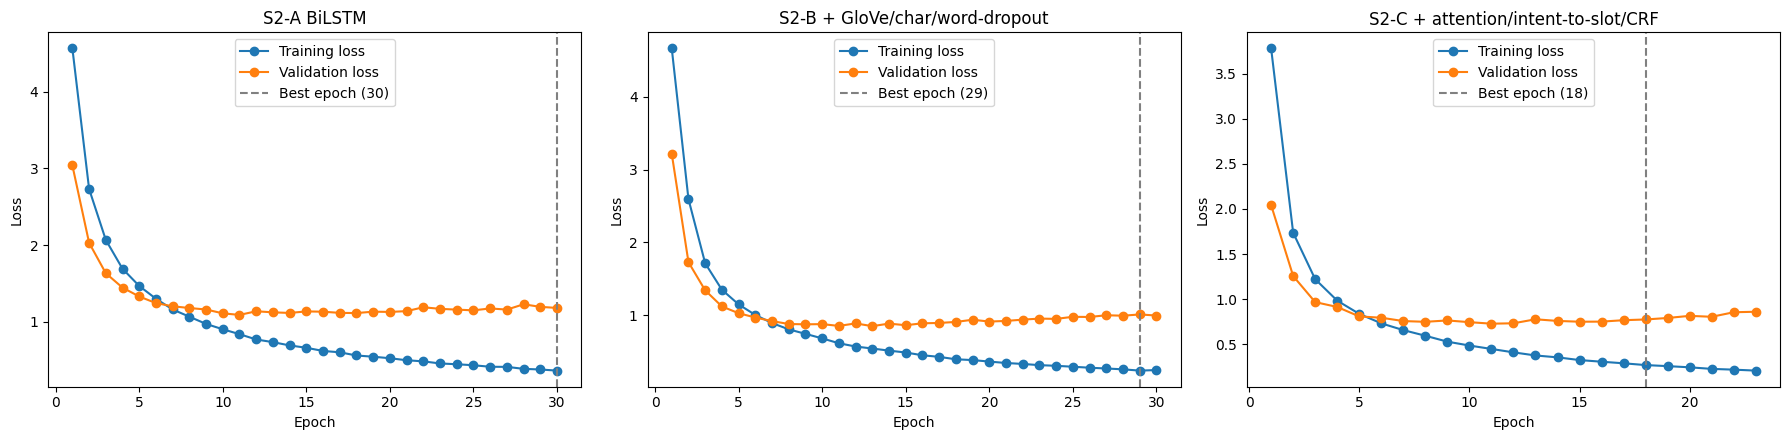

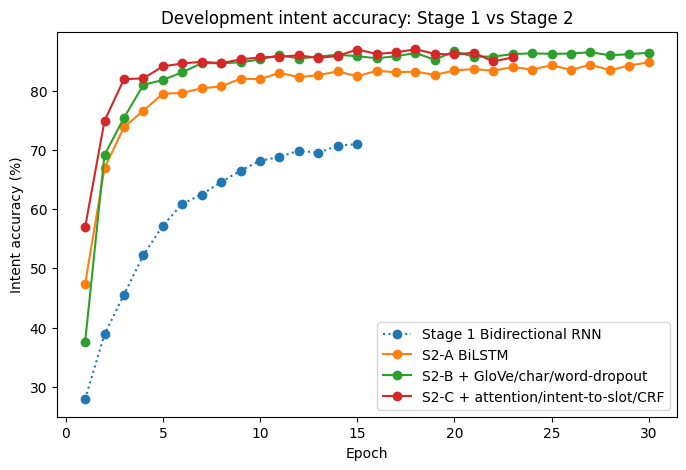

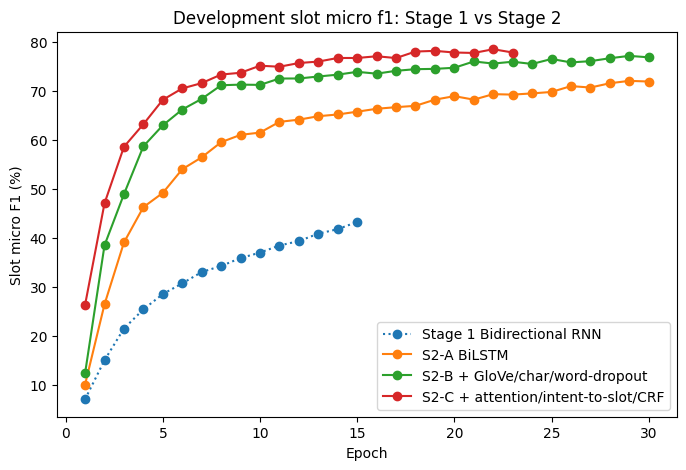

In [26]:
fig, axes = plt.subplots(1, len(stage2_runs), figsize=(6 * len(stage2_runs), 4.5))
for ax, (name, run) in zip(axes, stage2_runs.items()):
    h = run['history']
    ax.plot(h['epoch'], h['training_loss'], marker='o', label='Training loss')
    ax.plot(h['epoch'], h['validation_loss'], marker='o', label='Validation loss')
    ax.axvline(run['info']['best_epoch'], color='grey', linestyle='--',
               label=f"Best epoch ({run['info']['best_epoch']})")
    ax.set_title(name)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
plt.tight_layout()
plt.show()

for metric, label in [('dev_intent_accuracy', 'Intent accuracy (%)'), ('dev_slot_micro_f1', 'Slot micro F1 (%)')]:
    plt.figure(figsize=(8, 5))
    plt.plot(best_history['epoch'], best_history[metric], marker='o', linestyle=':',
             label=f'Stage 1 {best_name}')
    for name, run in stage2_runs.items():
        plt.plot(run['history']['epoch'], run['history'][metric], marker='o', label=name)
    plt.xlabel('Epoch')
    plt.ylabel(label)
    plt.title(f'Development {label.split(" (")[0].lower()}: Stage 1 vs Stage 2')
    plt.legend()
    plt.show()

## 28. Did Stage 2 fix the baseline's weaknesses? (dev set)

The same diagnosis as Section 19, now run on the selected Stage 2 model. The table puts both side by side, so each weakness W1–W5 can be checked directly.

In [27]:
stage2_diag = diagnose(data['dev'], stage2_runs[stage2_name]['dev_intents'],
                       stage2_runs[stage2_name]['dev_tags'], f'Stage 2 ({stage2_name}), dev set')

side_by_side = pd.DataFrame({'Stage 1 baseline': baseline_diag['summary'],
                             'Stage 2': stage2_diag['summary']})
side_by_side['Change'] = side_by_side['Stage 2'] - side_by_side['Stage 1 baseline']
print('\nSide by side (dev set):')
display(side_by_side.round(2))

errors_side = baseline_diag['slot_errors'][['Outcome', 'Count']].merge(
    stage2_diag['slot_errors'][['Outcome', 'Count']], on='Outcome', how='outer',
    suffixes=(' (Stage 1)', ' (Stage 2)')).fillna(0)
print('What happened to each gold slot, Stage 1 vs Stage 2:')
display(errors_side)

===== Stage 2 (S2-C + attention/intent-to-slot/CRF), dev set =====
  Intent accuracy (%)                              87.01
  Slot micro F1 (%)                                78.06
  Tokens not in training vocab (%)                 3.27
  Utterances with >=1 unknown word (%)             17.90
  Intent acc, utterances with unknown words (%)    75.55
  Slot F1, utterances with unknown words (%)       64.29
  Intent acc, utterances without unknown words (%) 89.51
  Slot F1, utterances without unknown words (%)    81.39
  Invalid I- tags predicted                        0

Performance by utterance length:


,Length (tokens),Utterances,Intent acc (%),Slot F1 (%)
0,1-4,448,81.70,76.26
1,5-8,1057,89.50,81.30
2,9-12,401,87.78,75.85
3,13+,127,82.68,71.67


10 worst intents:


,Intent,Support,Accuracy (%)
27,music_dislikeness,2,50.00
36,cooking_query,2,50.00
3,general_quirky,105,50.48
55,qa_maths,13,61.54
35,recommendation_events,26,65.38
47,recommendation_movies,12,75.00
9,audio_volume_down,8,75.00
33,qa_factoid,90,76.67
6,music_query,30,76.67
29,takeaway_order,20,80.00


10 most frequent intent confusions:


,True intent,Predicted intent,Count
0,general_quirky,qa_factoid,12
1,calendar_set,calendar_query,8
2,qa_factoid,general_quirky,8
3,general_quirky,news_query,7
4,music_query,play_music,4
5,general_quirky,datetime_query,4
6,recommendation_events,calendar_query,4
7,weather_query,general_quirky,3
8,news_query,qa_factoid,3
9,takeaway_order,takeaway_query,3


... (4 outputs left out)


Side by side (dev set):


,Stage 1 baseline,Stage 2,Change
Intent accuracy (%),70.98,87.01,16.04
Slot micro F1 (%),43.31,78.06,34.75
Tokens not in training vocab (%),3.27,3.27,0.00
Utterances with >=1 unknown word (%),17.90,17.90,0.00
"Intent acc, utterances with unknown words (%)",57.14,75.55,18.41
"Slot F1, utterances with unknown words (%)",22.76,64.29,41.52
"Intent acc, utterances without unknown words (%)",74.00,89.51,15.52
"Slot F1, utterances without unknown words (%)",47.45,81.39,33.95
Invalid I- tags predicted,172.00,0.00,-172.00


What happened to each gold slot, Stage 1 vs Stage 2:


,Outcome,Count (Stage 1),Count (Stage 2)
0,correct,693,1571
1,missed (nothing predicted there),1016,144
2,"right span, wrong type",38,85
3,"right type, wrong boundary",191,129
4,spurious (no gold slot there),89,162
5,wrong type and boundary,74,83


## 29. Error cases of the AI-improved system (test set)

The report needs at least two error cases from the improved system. The model is already frozen, so looking at test errors here does not affect any decision. Below are test utterances where the Stage 2 system got the **intent** wrong, and where it got the **slots** wrong, with gold and predicted values side by side. All Stage 2 test predictions are also saved to `stage2_outputs/test_predictions_stage2.csv`.

In [28]:
stage2_prediction_rows = []
for row, p_intent, p_tags in zip(data['test'], stage2_test_intents, stage2_test_tags):
    stage2_prediction_rows.append({
        'id': row['id'],
        'utterance': row['utt'],
        'true_intent': row['intent'],
        'predicted_intent': id2intent[p_intent],
        'true_slots': format_slot_values(row['tokens'], row['slots']),
        'predicted_slots': format_slot_values(row['tokens'], p_tags),
        'unknown_words': ' '.join(w for w in row['tokens'] if w not in vocab),
        'true_bio_tags': ' '.join(row['slots']),
        'predicted_bio_tags': ' '.join(p_tags),
    })
stage2_predictions = pd.DataFrame(stage2_prediction_rows)
stage2_predictions.to_csv(STAGE2_DIR / 'test_predictions_stage2.csv', index=False)

intent_errors = stage2_predictions[stage2_predictions['true_intent'] != stage2_predictions['predicted_intent']]
slot_errors = stage2_predictions[stage2_predictions['true_slots'] != stage2_predictions['predicted_slots']]
print(f'Test utterances with a wrong intent: {len(intent_errors):,} of {len(stage2_predictions):,}')
print(f'Test utterances with at least one slot error: {len(slot_errors):,} of {len(stage2_predictions):,}\n')

pd.set_option('display.max_colwidth', None)
print('Examples of intent errors:')
display(intent_errors[['utterance', 'true_intent', 'predicted_intent', 'unknown_words']]
        .sample(min(8, len(intent_errors)), random_state=SEED))
print('Examples of slot errors (intent correct):')
slot_only = slot_errors[slot_errors['true_intent'] == slot_errors['predicted_intent']]
display(slot_only[['utterance', 'true_slots', 'predicted_slots', 'unknown_words']]
        .sample(min(8, len(slot_only)), random_state=SEED))

# save tables for the report
comparison.to_csv(STAGE2_DIR / 'stage1_vs_stage2.csv', index=False, float_format='%.2f')
dev_table.to_csv(STAGE2_DIR / 'stage2_dev_table.csv', index=False, float_format='%.2f')
side_by_side.to_csv(STAGE2_DIR / 'diagnosis_side_by_side.csv', float_format='%.2f')
for name, run in stage2_runs.items():
    run['history'].to_csv(STAGE2_DIR / f"history_{name.split()[0]}.csv", index=False)
print('Files saved in:', STAGE2_DIR.resolve())

Test utterances with a wrong intent: 427 of 2,974
Test utterances with at least one slot error: 793 of 2,974

Examples of intent errors:


,utterance,true_intent,predicted_intent,unknown_words
2845,make a call to,email_querycontact,transport_taxi,
569,turn down the lights to medium,iot_hue_lightoff,iot_hue_lightdim,
1185,friend updates,general_quirky,news_query,
197,get sia's cheap thrills ready to play next,play_music,general_quirky,sia's thrills
2441,how far is canada from my current location,qa_factoid,transport_query,
2014,start playing ringcast,play_podcasts,play_music,
1128,today the following happened to me i had a meeting with george,general_quirky,calendar_query,
1125,hello how is your day,general_quirky,general_greet,


Examples of slot errors (intent correct):


,utterance,true_slots,predicted_slots,unknown_words
669,play me last year's hits,No slots detected,[playlist_name: last year's hits],
2205,train times from near me to location,[place_name: location],[transport_type: train],
794,read me the latest headlines from nytimescom,[media_type: nytimescom],[news_topic: nytimescom],
477,the second of next mont lands on what day,[event_name: second of next mont lands],No slots detected,mont
1858,remove the list called party time,[list_name: party time],[event_name: party],
1502,within the past three months how many meetings did i have with mr. richards,[time: past three months]; [event_name: meetings]; [person: mr . richards],[event_name: meetings]; [person: mr . richards],
98,what mistakes do you usually make,No slots detected,[person: mistakes],mistakes
2896,what is mr. taxi's phone number it is in my contacts,[business_name: mr . taxi's]; [personal_info: phone number],[person: mr . taxi's]; [personal_info: phone number],taxi's


Files saved in: /content/stage2_outputs


## 30. Predict an intent and slots for a new utterance (Stage 2)

Same example as Section 18, now with the Stage 2 system, plus two utterances containing words that are not in the training vocabulary.

In [29]:
def predict_utterance_stage2(utterance):
    words = tokenize_utterance(utterance) or [UNK_TOKEN]
    word_ids = torch.tensor([[vocab.get(w, UNK_ID) for w in words]], device=DEVICE)
    char_ids = [[char_vocab.get(ch, CHAR_UNK_ID) for ch in w[:MAX_WORD_LEN]] or [CHAR_UNK_ID] for w in words]
    chars = torch.zeros(1, len(words), max(len(c) for c in char_ids), dtype=torch.long)
    for j, c in enumerate(char_ids):
        chars[0, j, :len(c)] = torch.tensor(c)
    lengths = torch.tensor([len(words)])

    stage2_model.eval()
    with torch.no_grad():
        intents, tag_ids = stage2_model.predict(word_ids, chars.to(DEVICE), lengths)
    tags = [id2slot[t] for t in tag_ids[0]]
    return {'utterance': utterance, 'predicted_intent': id2intent[intents[0]], 'tokens': words,
            'unknown_words': [w for w in words if w not in vocab],
            'predicted_slots': extract_slot_values(words, tags), 'predicted_bio_tags': tags}


for text in ['Set an alarm for 7 am tomorrow',
             'play some music by zubeen garg',
             'remind me to call grandma kowalczyk at 6 pm']:
    result = predict_utterance_stage2(text)
    print('Utterance:', result['utterance'])
    print('Predicted intent:', result['predicted_intent'])
    print('Unknown words:', result['unknown_words'] or 'none')
    print('Extracted slots:', '; '.join(result['predicted_slots']) or 'No slots detected')
    print('BIO tags:', result['predicted_bio_tags'])
    print()

Utterance: Set an alarm for 7 am tomorrow
Predicted intent: alarm_set
Unknown words: ['7']
Extracted slots: [time: 7 am]; [date: tomorrow]
BIO tags: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'B-date']

Utterance: play some music by zubeen garg
Predicted intent: play_music
Unknown words: ['zubeen', 'garg']
Extracted slots: [artist_name: zubeen garg]
BIO tags: ['O', 'O', 'O', 'O', 'B-artist_name', 'I-artist_name']

Utterance: remind me to call grandma kowalczyk at 6 pm
Predicted intent: calendar_set
Unknown words: ['kowalczyk', '6', 'pm']
Extracted slots: [relation: grandma kowalczyk]; [person: 6 pm]
BIO tags: ['O', 'O', 'O', 'O', 'B-relation', 'I-relation', 'O', 'B-person', 'I-person']



## 31. Stage 2 summary

The numbers for the report come from the outputs above:
- **Stage 1 vs Stage 2, dev and test:** Section 26 (`stage2_outputs/stage1_vs_stage2.csv`).
- **What each group of AI suggestions contributed (S2-A → S2-B → S2-C), dev only:** Section 25.
- **Whether each baseline weakness was fixed:** Section 28.
- **Error cases of the improved system:** Section 29.

**Limitations to discuss in the report**
- All Stage 2 hyperparameters are common defaults chosen before training. Only early stopping and the choice between S2-A/B/C used the dev set, so a wider dev search might do better.
- Each configuration was trained with one seed. Small differences (under about 0.5 points) between steps may be random variation rather than real improvements.
- GloVe was trained on Wikipedia and news text, not on spoken assistant requests, so some assistant-specific words still start from random vectors.
- The vocabulary is still built only from training words. Unseen words rely on `<UNK>` plus their characters, so slot types made of rare names (for example people, places and song titles) are likely to stay among the hardest.